# 02_ViT_CIFAR10 — 셀별 코드 해설 노트북 (Python 초보용)

이 노트북은 원본 `02_ViT_CIFAR10.ipynb`와 **코드가 완전히 같습니다.** 달라진 점은 `# 1`, `# 2` … 처럼 번호가 붙은 코드 셀 **바로 위에** "[셀 # N] 코드 설명" 칸이 하나씩 추가된 것뿐입니다.

**읽는 방법**

1. 원래 있던 섹션 설명(목적 / 관찰 포인트)을 읽습니다.
2. 추가된 "[셀 # N] 코드 설명"을 읽습니다. — *한 줄 요약 → 코드 흐름 → Python 초보 포인트* 순서입니다.
3. 그 아래 코드 셀을 설명과 한 줄씩 맞춰 보면서 실행합니다.

**이 노트북 전체에서 반복해서 나오는 말**

| 용어 | 쉬운 뜻 |
|---|---|
| 텐서(tensor) | 숫자가 여러 겹으로 담긴 상자. 리스트 안에 리스트가 들어 있는 것과 비슷하지만 GPU로 빠르게 계산할 수 있습니다. |
| shape | 텐서의 "모양". `(256, 3, 32, 32)`는 "이미지 256장, 색 3채널, 세로 32, 가로 32"라는 뜻입니다. |
| B, C, H, W | Batch(한 번에 넣는 장수), Channel(색 채널), Height(세로), Width(가로) |
| 토큰(token) | Transformer가 다루는 한 조각. ViT에서는 **이미지를 자른 작은 패치 하나**가 토큰 하나입니다. |
| epoch | 학습 데이터 전체를 한 바퀴 다 보는 것 |
| loss | 모델이 얼마나 틀렸는지를 나타내는 숫자. 작을수록 좋습니다. |

**ViT를 한 문장으로:** 이미지를 4×4 조각 64개로 자르고 → 각 조각을 숫자 벡터로 바꾼 뒤 → "조각들끼리 서로 얼마나 관련 있는지(Attention)"를 여러 번 계산해서 → 맨 앞에 붙여 둔 CLS 토큰으로 10개 클래스 중 하나를 고르는 모델입니다.

---

# **Vision Transformer with CIFAR-10 — 패치 임베딩부터 분류까지**

**Vision Transformer(ViT)** 실습을 목표로 합니다.  
CNN과 달리 ViT는 이미지를 **패치(patch) 시퀀스**로 바꾼 뒤, NLP의 Transformer Encoder와 거의 같은 방식으로 처리합니다.

## 학습 목표
- 이미지를 **패치 토큰**으로 바꾸는 과정(= Patch Embedding)을 이해한다.
- **[CLS] 토큰 + Positional Embedding** 이 왜 필요한지 설명할 수 있다.
- Transformer Encoder의 핵심 구성(**Pre-LN / MHSA / FFN / Residual**)을 코드에서 찾아 읽을 수 있다.
- 학습 후 **오분류(실패) 샘플**을 통해 모델의 한계를 분석한다.

> 권장 흐름: (1) 데이터/전처리 → (2) ViT 구성 → (3) 학습/평가 → (4) 오분류 분석


---
## 0) Setup (환경 준비)

- **목적:** 실습에 필요한 패키지를 로드하고, 재현 가능한 실험을 위해 시드를 고정합니다.
- **관찰 포인트**
  - 실습에 필요한 유틸 패키지(`einops`, `torchinfo` 등) 준비
  - GPU 사용 여부(`cuda`) 확인

### [셀 # 1] 코드 설명

**한 줄 요약:** 실습에 필요한 라이브러리(`einops`, `torchinfo`)가 내 컴퓨터에 깔려 있는지 확인하고, 없으면 자동으로 설치합니다.

**코드 흐름**

1. `import importlib.util`, `subprocess`, `sys` — Python에 기본으로 들어 있는 도구 3개를 불러옵니다. 각각 "패키지가 있는지 찾아보기", "다른 프로그램(pip) 실행하기", "지금 쓰는 Python 정보 보기" 용도입니다.
2. `def ensure_package(...)` — "패키지 확인 후 없으면 설치"라는 동작을 **함수**로 묶어 둡니다.
   - `name = import_name or pkg_name` : `import_name`을 안 줬으면(=`None`) `pkg_name`을 대신 씁니다. 설치할 때 이름과 `import` 할 때 이름이 다른 패키지(예: 설치는 `Pillow`, import는 `PIL`)를 위한 장치입니다.
   - `importlib.util.find_spec(name) is None` : 그 이름의 패키지를 찾지 못하면 `None`이 나옵니다. 즉 "설치 안 됨"이라는 뜻입니다.
   - `subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg_name])` : 터미널에서 `python -m pip install -q 패키지명`을 친 것과 같습니다. `sys.executable`은 "지금 이 노트북이 쓰고 있는 바로 그 Python"이라서, 엉뚱한 Python에 설치되는 실수를 막아 줍니다.
3. `packages = [("einops", "einops"), ("torchinfo", "torchinfo")]` — (설치 이름, import 이름) 쌍의 목록입니다.
4. `for pkg, imp in packages:` — 목록을 하나씩 꺼내 함수를 호출합니다.

**Python 초보 포인트**

- `pkg_name: str` 의 `: str`은 **타입 힌트**입니다. "여기엔 문자열을 넣어 주세요"라는 메모일 뿐, 실행에는 영향이 없습니다.
- `import_name=None` 은 **기본값**입니다. 함수를 부를 때 이 값을 생략할 수 있습니다.
- `f"... {pkg_name} ..."` 는 **f-string**입니다. 중괄호 안의 변수 값이 문자열 속에 끼워 넣어집니다.
- `try: ... except ... as e:` 는 "일단 해 보고, 에러가 나면 프로그램을 멈추지 말고 이쪽을 실행하라"는 구문입니다.
- `for pkg, imp in packages:` 처럼 쉼표로 변수 두 개를 쓰면 튜플 `("einops", "einops")`가 자동으로 둘로 나뉘어 담깁니다(**언패킹**).

In [1]:
# 1
import importlib.util
import subprocess
import sys

def ensure_package(pkg_name: str, import_name=None):
    """
    패키지 설치 여부를 확인하고, 설치되어 있지 않으면 설치합니다.
    """
    name = import_name or pkg_name
    # 패키지가 설치되어 있는지 확인
    if importlib.util.find_spec(name) is None:
        print(f"[install] {pkg_name} 라이브러리를 설치 중입니다... (import name: {name})")
        try:
            # -q 옵션을 추가하여 설치 과정을 간결하게 유지할 수 있습니다.
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg_name])
            print(f"[success] {pkg_name} 설치 완료.")
        except subprocess.CalledProcessError as e:
            print(f"[error] {pkg_name} 설치 실패: {e}")
    else:
        print(f"[ok] {pkg_name} 이미 설치되어 있습니다.")

# 설치가 필요한 패키지 리스트 (패키지명, 임포트명)
# 임포트명이 패키지명과 다른 경우 튜플로 지정합니다.
packages = [
    ("einops", "einops"),
    ("torchinfo", "torchinfo")
]

# 루프를 돌며 확인 및 설치
for pkg, imp in packages:
    ensure_package(pkg, imp)

[ok] einops 이미 설치되어 있습니다.
[ok] torchinfo 이미 설치되어 있습니다.


### [셀 # 2] 코드 설명

**한 줄 요약:** 딥러닝에 쓸 도구들을 불러오고(import), GPU를 쓸 수 있는지 확인한 뒤, 계산할 장치를 `device` 변수에 정해 둡니다.

**코드 흐름**

1. `import torch` 및 `from torch import nn, optim ...` — PyTorch 본체와 그 안의 부품들입니다.
   - `nn` : 신경망 층(Linear, LayerNorm 등)을 모아 둔 곳
   - `F` (`torch.nn.functional`) : 층을 만들지 않고 바로 호출하는 함수형 도구(softmax, loss 등)
   - `optim` : 가중치를 고쳐 주는 옵티마이저(Adam 등)
   - `einsum` : 여러 축의 곱셈/합을 문자열 한 줄로 표현하는 도구(5번 셀에서 사용)
2. `from einops import rearrange, repeat` / `Rearrange` — 텐서의 모양을 `"b c h w -> b h w c"` 같은 글자로 바꾸는 도구입니다. ViT에서 이미지를 패치로 자를 때 씁니다.
3. `print(torch.__version__)` … — 버전과 GPU 사용 가능 여부를 화면에 찍어 환경을 확인합니다.
4. `get_ipython().system('nvidia-smi -L')` — 주피터에서 터미널 명령 `nvidia-smi -L`(GPU 목록 보기)을 실행합니다. GPU가 없는 환경이면 에러가 나므로 `try/except`로 감싸 두었습니다.
5. `device = torch.device("cuda" if torch.cuda.is_available() else "cpu")` — GPU가 있으면 `"cuda"`, 없으면 `"cpu"`를 고릅니다. 이후 모델과 데이터를 `.to(device)`로 이 장치에 올립니다.

**Python 초보 포인트**

- `import A as B` 는 "A를 B라는 짧은 별명으로 부르겠다"는 뜻입니다.
- `from A import B` 는 "A 안의 B만 꺼내 오겠다"는 뜻입니다.
- `값1 if 조건 else 값2` 는 한 줄짜리 if 문(**조건 표현식**)입니다.
- `nn`이 두 번 import 되어 있지만(`from torch import nn`이 2줄) 같은 것을 다시 불러올 뿐이라 문제는 없습니다.

In [2]:
# 2
import torch
from torch import nn
from torch import nn, einsum
import torch.nn.functional as F  # 함수형 API(F): activation/loss 등
from torch import optim

from einops import rearrange, repeat  # ViT에서 자주 쓰는 텐서 재배열(rearrange)·복제(repeat)
from einops.layers.torch import Rearrange
import numpy as np
import torchvision  # 데이터/변환(torchvision) 사용 (CIFAR-10 포함)
import time
from torchinfo import summary

print('torch:', torch.__version__)  # torch 버전 출력
print('torchvision:', torchvision.__version__)  # torchvision 버전 출력
print('cuda available:', torch.cuda.is_available())  # GPU 사용 가능 여부
if torch.cuda.is_available():
    print('gpu:', torch.cuda.get_device_name(0))  # GPU 이름 출력

try:
    get_ipython().system('nvidia-smi -L')  # GPU 목록 확인(가능한 경우)
except Exception as e:
    print('nvidia-smi not available:', e)  # nvidia-smi가 없는 환경이면 무시

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


torch: 2.11.0+cu128
torchvision: 0.26.0+cu128
cuda available: True
gpu: NVIDIA GeForce RTX 5070 Laptop GPU
GPU 0: NVIDIA GeForce RTX 5070 Laptop GPU (UUID: GPU-2838d089-1e8d-7915-299b-14b803b0ccbc)
Using device: cuda


---
## 1) 데이터 로딩 & 전처리

- **목적:** CIFAR-10(컬러 32×32)를 로드하고, 모델 입력 텐서 형태를 확인합니다.
- **관찰 포인트**
  - 입력 텐서 shape: `B×C×H×W` (CIFAR-10는 `C=3`)
  - 학습/테스트 로더 구성과 배치 단위 학습의 의미


### [셀 # 3] 코드 설명

**한 줄 요약:** CIFAR-10 이미지 데이터를 내려받고, 모델이 먹기 좋은 형태(정규화된 텐서)로 바꾼 다음, 256장씩 묶어서 꺼내 주는 `DataLoader`를 만듭니다.

**코드 흐름**

1. `CIFAR10_MEAN`, `CIFAR10_STD` — 빨강/초록/파랑 채널별 평균과 표준편차입니다. 정규화에 씁니다.
2. `train_tfms = T.Compose([...])` — 학습용 이미지에 **순서대로** 적용할 변환 목록입니다.
   - `RandomCrop(32, padding=4)` : 테두리에 4픽셀을 덧댄 뒤 32×32를 무작위로 잘라냅니다(이미지가 조금씩 밀린 효과).
   - `RandomHorizontalFlip()` : 50% 확률로 좌우를 뒤집습니다.
   - `ToTensor()` : 그림 파일(PIL)을 0~1 사이 숫자 텐서 `(3, 32, 32)`로 바꿉니다.
   - `Normalize(mean, std)` : `(값 - 평균) / 표준편차`. 숫자 범위를 고르게 맞춰 학습이 잘 되게 합니다.
3. `test_tfms` — 평가용은 무작위 변형 없이 텐서 변환 + 정규화만 합니다(시험 문제는 바꾸면 안 되니까요).
4. `torchvision.datasets.CIFAR10(root, train=True/False, download=True, transform=...)` — `./data` 폴더에 데이터가 없으면 내려받습니다. 학습용 50,000장, 평가용 10,000장입니다.
5. `class_names = train_set.classes` — `['airplane', 'automobile', ...]` 10개 클래스 이름 목록입니다.
6. `x0, y0 = train_set[0]` — 0번째 샘플을 꺼내면 `(이미지 텐서, 정답 번호)` 쌍이 나옵니다. shape가 `(3, 32, 32)`인지 확인합니다.
7. `DataLoader(...)` — 데이터를 `batch_size=256`장씩 묶어 줍니다.
   - `shuffle=True` : 학습용은 매 epoch마다 순서를 섞습니다. 평가용은 섞지 않습니다.
   - `num_workers` : 데이터를 준비하는 보조 프로세스 수
   - `pin_memory=True` : GPU로 옮기는 속도를 조금 높여 주는 옵션
8. `len(train_loader)` — 배치 개수입니다. 50,000 ÷ 256 → 196개, 10,000 ÷ 256 → 40개.

**Python 초보 포인트**

- `(0.4914, 0.4822, 0.4465)` 처럼 소괄호로 묶은 것은 **튜플**입니다. 리스트와 비슷하지만 값을 바꿀 수 없습니다.
- `os.cpu_count() or 2` : 앞의 값이 `None`이면 뒤의 `2`를 씁니다. `min(8, ...)`은 둘 중 작은 값입니다.
- `'... %d ...' % (a, b)` 는 f-string 이전의 옛날식 문자열 끼워넣기입니다. `%d` 자리에 정수가 들어갑니다.
- **Windows 사용자 참고:** 이 셀이나 다음 셀에서 멈추거나 에러가 나면 `num_workers = 0`으로 바꿔 보세요. Windows에서는 보조 프로세스 방식 때문에 문제가 생기는 경우가 있습니다.

In [3]:
# 3
import os
import torchvision
import torchvision.transforms as T
from torch.utils.data import DataLoader

# CIFAR-10에서 널리 쓰는 normalize 값
CIFAR10_MEAN = (0.4914, 0.4822, 0.4465)  # 채널별 평균(R,G,B)
CIFAR10_STD  = (0.2023, 0.1994, 0.2010)  # 채널별 표준편차(R,G,B)

train_tfms = T.Compose([  # train transform(augmentation 포함)
    T.RandomCrop(32, padding=4),      # 32x32를 padding 후 random crop
    T.RandomHorizontalFlip(),         # 좌우 반전
    T.ToTensor(),                     # PIL -> torch tensor (C,H,W)
    T.Normalize(CIFAR10_MEAN, CIFAR10_STD),  # 정규화
])

test_tfms = T.Compose([  # test transform(augmentation 없음)
    T.ToTensor(),                     # 텐서 변환
    T.Normalize(CIFAR10_MEAN, CIFAR10_STD),  # 정규화
])

data_root = './data'  # 데이터 저장 경로
train_set = torchvision.datasets.CIFAR10(root=data_root, train=True, download=True, transform=train_tfms)  # train set
test_set  = torchvision.datasets.CIFAR10(root=data_root, train=False, download=True, transform=test_tfms)  # test set

class_names = train_set.classes  # 클래스 이름 목록
num_classes = len(class_names)   # 클래스 개수(10)
print('classes:', class_names)   # 클래스 출력

# 이미지 사이즈 출력
x0, y0 = train_set[0]  # 한 샘플 로드(이미 transform 적용된 텐서)
print('Sample image tensor shape (C,H,W):', tuple(x0.shape))  # (3,32,32)

batch_size = 256  # 배치 크기(A10이면 보통 여유)
num_workers = min(8, os.cpu_count() or 2)  # dataloader worker 수(환경에 맞게)

train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True, num_workers=num_workers, pin_memory=True)  # train loader
test_loader  = DataLoader(test_set, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=True)  # test loader

print('Total batch size (train: %d, test: %d)' % (len(train_loader), len(test_loader)))  # 배치 개수 확인


C:\Users\bioyo\AppData\Local\Programs\Python\Python311\Lib\site-packages\torchvision\datasets\cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Sample image tensor shape (C,H,W): (3, 32, 32)
Total batch size (train: 196, test: 40)


### [셀 # 4] 코드 설명

**한 줄 요약:** 학습 데이터 한 묶음에서 16장을 꺼내 4×4 격자 그림으로 보여 주는 함수를 만들고, 실제로 그려 봅니다.

**코드 흐름**

1. `denormalize_cifar10(img_chw)` — 3번 셀에서 정규화했던 것을 **거꾸로** 되돌립니다. 정규화가 `(x - mean) / std` 였으므로 복원은 `x * std + mean` 입니다. 그대로 그리면 색이 이상하게 나오기 때문입니다.
   - `torch.tensor(CIFAR10_MEAN)[:, None, None]` : 길이 3짜리 `(3,)`를 `(3, 1, 1)` 모양으로 바꿉니다. 이렇게 해야 `(3, H, W)` 이미지의 채널별로 값이 자동으로 맞춰져 계산됩니다(**브로드캐스팅**).
   - `.clamp(0, 1)` : 0보다 작은 값은 0, 1보다 큰 값은 1로 잘라냅니다.
2. `show_batch(...)`
   - `batch = next(iter(data_loader))` : DataLoader에서 **첫 묶음 하나**만 꺼냅니다.
   - `images, labels = batch` : (이미지 256장, 정답 256개)로 나눕니다.
   - `images[:max_images]` : 앞에서 16장만 자릅니다(**슬라이싱**).
   - `torchvision.utils.make_grid(images, nrow=4, padding=2)` : 16장을 한 줄에 4장씩 이어 붙여 큰 이미지 한 장으로 만듭니다.
   - `.detach().cpu().numpy().transpose((1, 2, 0))` : 그리기 위한 4단계 변환입니다. ① 학습 기록에서 떼어내고 ② CPU로 옮기고 ③ numpy 배열로 바꾸고 ④ 축 순서를 `(C,H,W)` → `(H,W,C)`로 바꿉니다. PyTorch는 채널이 맨 앞, matplotlib은 채널이 맨 뒤이기 때문입니다.
   - `plt.subplots`, `ax.imshow`, `ax.axis("off")` : 도화지를 만들고, 그림을 올리고, 눈금을 숨깁니다.
3. 마지막 두 줄에서 `show_batch`를 **두 번** 부릅니다. `shuffle=True`라서 부를 때마다 다른 16장이 나옵니다. (같은 줄이 두 번 있는 것은 오타가 아니라 "다른 샘플도 한 번 더 보기" 정도로 이해하면 됩니다.)

**Python 초보 포인트**

- 함수 첫 줄 아래의 `"""..."""` 는 **독스트링**(함수 설명서)입니다. 실행되지 않습니다.
- `max_images: int = 16` 은 "정수를 받고, 생략하면 16"이라는 뜻입니다.
- `a.b().c().d()` 처럼 점으로 이어 쓰면 앞 결과에 다음 동작을 차례로 적용합니다(**메서드 체이닝**).

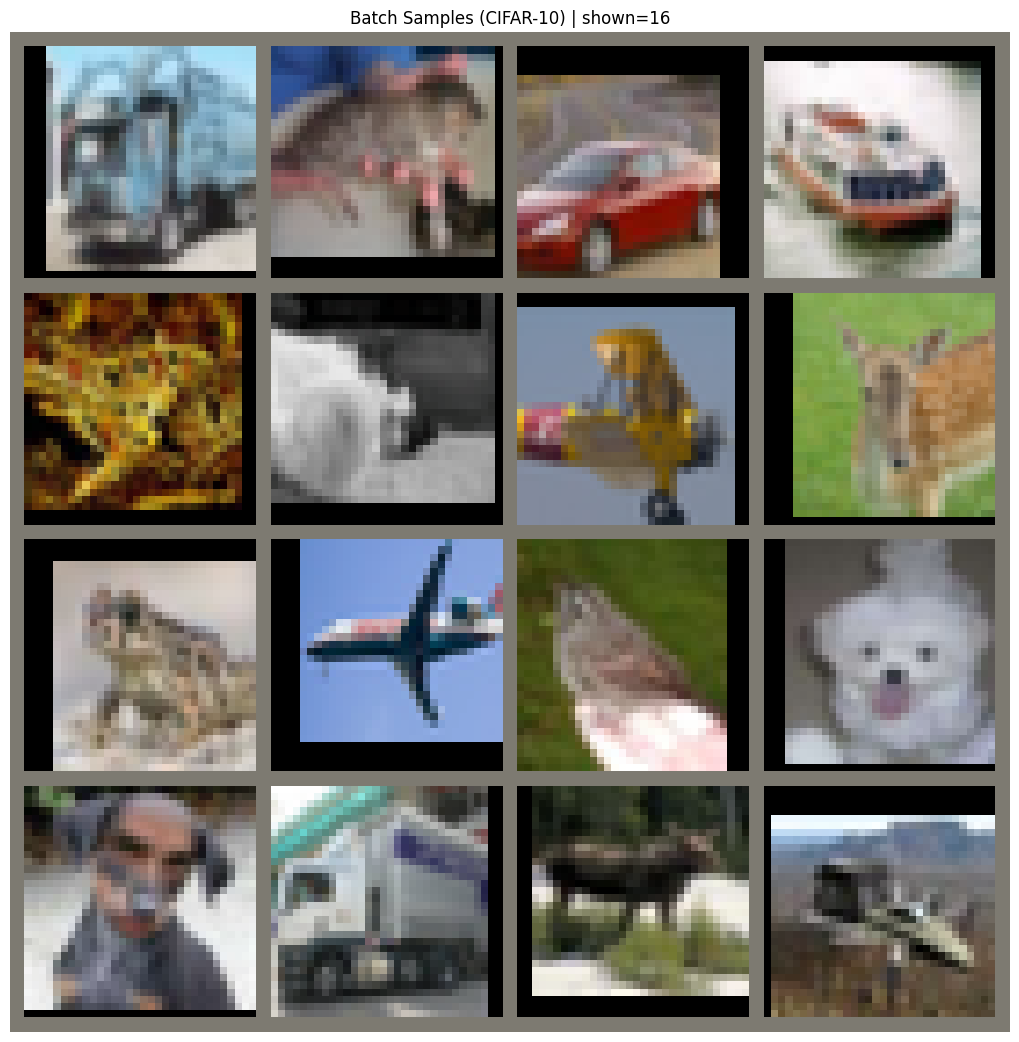

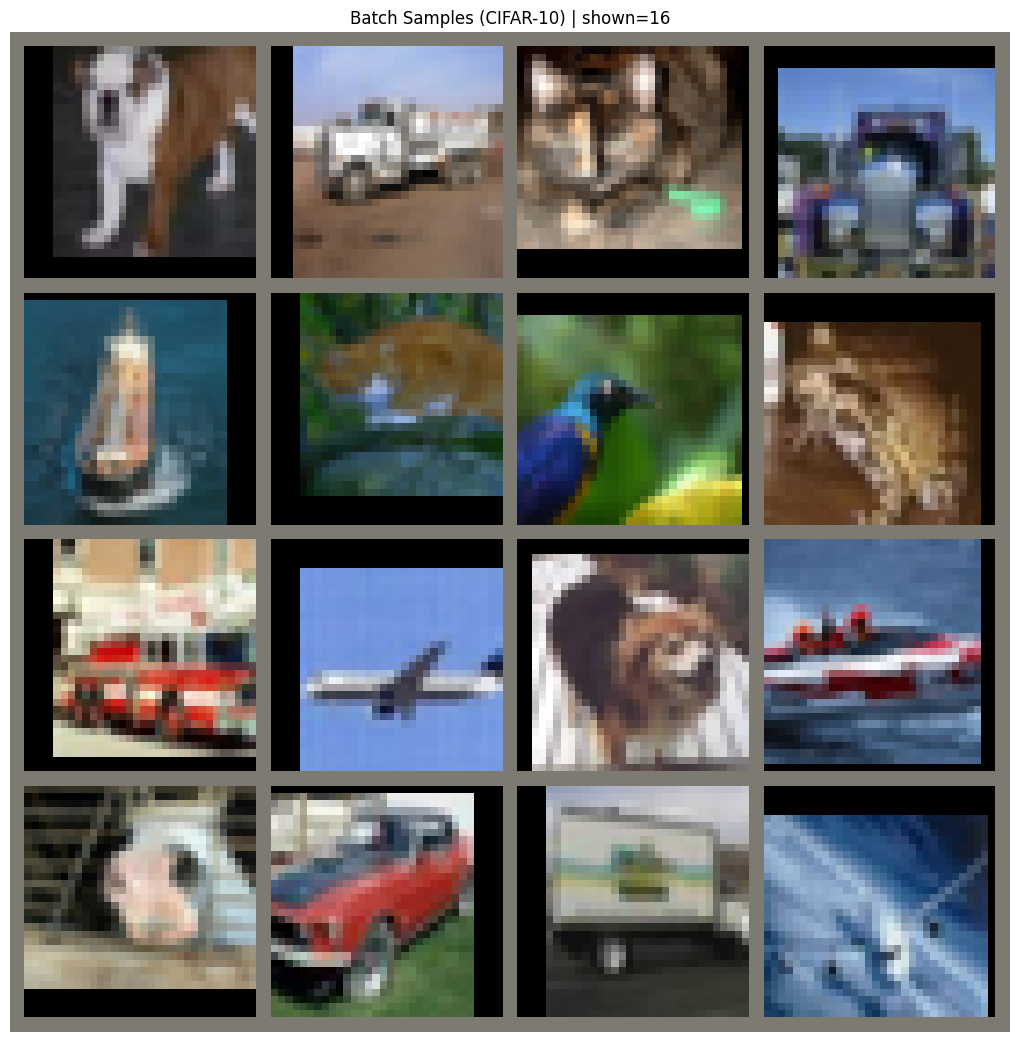

In [4]:
# 4
import matplotlib.pyplot as plt
import torch

def denormalize_cifar10(img_chw: torch.Tensor):
    """정규화된 CIFAR-10 텐서(C,H,W)를 시각화용(0~1)으로 되돌립니다."""
    mean = torch.tensor(CIFAR10_MEAN, device=img_chw.device)[:, None, None]
    std  = torch.tensor(CIFAR10_STD,  device=img_chw.device)[:, None, None]
    x = img_chw * std + mean
    return x.clamp(0, 1)

def show_batch(data_loader, max_images: int = 16, nrow: int = 4, figsize=(10, 10)):
    """배치에서 일부 샘플을 보기 좋게 시각화합니다.

    - 기본값은 16장(4×4)을 비교적 크게 보여주는 설정입니다.
    - max_images/nrow/figsize를 바꾸면 '더 적게/더 많이', '더 크게/더 작게'를 조절할 수 있습니다.

    - CIFAR-10은 (C,H,W)=(3,32,32) RGB이므로, 시각화할 때는 (H,W,C)로 바꿔야 합니다.
    - make_grid 결과가 figure 안에서 '밀려 보이는' 경우가 있어, subplot 여백을 0으로 맞춰 꽉 차게 표시합니다.

    Args:
        data_loader: DataLoader
        max_images: 한 번에 보여줄 이미지 개수(기본 16장)
        nrow: grid 한 줄에 배치할 이미지 개수(기본 4개)
        figsize: figure 크기
    """
    batch = next(iter(data_loader))
    images, labels = batch  # images: (B,C,H,W)
    images = images[:max_images]

    # make_grid는 (B,C,H,W) → grid(C,H,W)
    grid = torchvision.utils.make_grid(images, nrow=nrow, padding=2)

    # 시각화는 정규화 해제 후 HWC로 변환
    grid = denormalize_cifar10(grid).detach().cpu().numpy().transpose((1, 2, 0))

    fig, ax = plt.subplots(figsize=figsize)
    ax.imshow(grid, interpolation="nearest")
    ax.set_title(f"Batch Samples (CIFAR-10) | shown={len(images)}")
    ax.axis("off")

    # 여백 제거: grid가 4×4에 꽉 차도록
    fig.subplots_adjust(left=0, right=1, bottom=0, top=1)
    plt.show()

# 미리보기: 크게(figure) + 적게(16장) 보기
show_batch(train_loader, max_images=16, nrow=4, figsize=(10, 10))
show_batch(train_loader, max_images=16, nrow=4, figsize=(10, 10))


---
## 2) ViT 모델 구성 개요

ViT는 크게 아래 3단계로 이해하면 읽기 쉬워집니다.

1. **Patch Embedding**  
   이미지(`H×W`)를 `P×P` 패치로 잘라 **토큰 시퀀스**로 바꾸고, 각 패치를 `dim` 차원으로 임베딩합니다.

2. **Transformer Encoder (× depth)**  
   토큰 시퀀스에 대해 반복적으로  
   **(Pre-LN → Multi-Head Self-Attention → Residual) + (Pre-LN → FFN → Residual)** 를 수행합니다.

3. **Classification Head**  
   보통 `[CLS]` 토큰(또는 평균 풀링)을 사용해 최종 분류 로짓을 출력합니다.

> 아래 코드에서 `dim / depth / heads / mlp_dim` 이 무엇을 의미하는지 주석과 함께 확인해 보세요.


### [셀 # 5] 코드 설명

**한 줄 요약:** ViT의 심장부인 Transformer 부품들 — 정규화(PreNorm), 작은 신경망(FeedForward), 어텐션(Attention), 그리고 이들을 여러 층 쌓은 것(Transformer) — 을 클래스로 만듭니다.

**먼저: PyTorch에서 "층(레이어)"을 만드는 공통 틀**

```python
class 이름(nn.Module):
    def __init__(self, ...):   # 부품을 "준비"하는 곳 (한 번만 실행)
        super().__init__()     # nn.Module의 기본 준비를 먼저 실행 (꼭 써야 함)
        self.부품 = ...
    def forward(self, x):      # 데이터가 "지나가는" 길 (모델(x) 할 때마다 실행)
        return ...
```

**코드 흐름**

1. `pair(t)` — 숫자 `4`가 들어오면 `(4, 4)`로, 이미 튜플이면 그대로 돌려줍니다.
2. `PreNorm` — "먼저 `LayerNorm`으로 숫자 크기를 고르게 한 다음, 맡겨진 함수 `fn`을 실행"하는 포장지입니다. `fn` 자리에 Attention이나 FeedForward가 들어옵니다.
3. `FeedForward` — `Linear(64→128) → ReLU → Dropout → Linear(128→64) → Dropout`. 토큰 하나하나를 따로 한 번 더 가공합니다. `nn.Sequential`은 안에 넣은 층들을 순서대로 통과시켜 줍니다. *(주석에는 GELU라고 적혀 있지만 실제 코드는 `nn.ReLU()`입니다.)*
4. `Attention` — "각 토큰이 다른 토큰들을 얼마나 참고할지" 계산합니다. 이 노트북 설정(토큰 65개, dim 64, head 4개) 기준으로 모양을 따라가 보면:
   - 입력 `x` : `(B, 65, 64)`
   - `self.to_qkv(x)` : `(B, 65, 768)` → `.chunk(3, dim=-1)` 로 3등분 → Q, K, V 각각 `(B, 65, 256)`
   - `rearrange(t, 'b n (h d) -> b h n d', h=4)` : 256을 4(head)×64로 쪼개 `(B, 4, 65, 64)`
   - `einsum('b h i d, b h j d -> b h i j', q, k) * self.scale` : 모든 토큰 쌍의 유사도 점수 `(B, 4, 65, 65)`. 값이 너무 커지지 않게 `1/√64`을 곱합니다.
   - `self.attend(dots)` : softmax로 점수를 "합이 1인 비율"로 바꿉니다. 이것이 **attention map**입니다.
   - `self.last_attn = attn.detach()` : 나중에 그림으로 보려고 저장해 둡니다(13번 셀에서 사용).
   - `einsum('b h i j, b h j d -> b h i d', attn, v)` : 비율대로 V를 섞어 새 토큰 표현을 만듭니다.
   - `rearrange(out, 'b h n d -> b n (h d)')` : head들을 다시 합쳐 `(B, 65, 256)` → `to_out`에서 `(B, 65, 64)`로 되돌립니다.
5. `Transformer` — `(Attention, FeedForward)` 한 쌍을 `depth`번(6번) 쌓습니다. `forward`의 `x = attn(x) + x` 는 **잔차 연결(residual)**: 계산 결과에 원래 입력을 더해 정보가 사라지지 않게 합니다.

**Python 초보 포인트**

- `def forward(self, x, **kwargs)` 의 `**kwargs` 는 "이름 붙은 추가 인자가 오면 뭐든 받아서 그대로 넘기겠다"는 뜻입니다.
- `b, n, _, h = *x.shape, self.heads` : `*x.shape`가 `(B, 65, 64)`를 풀어 놓고, 뒤에 heads를 붙여 4개 변수에 나눠 담습니다. `_` 는 "안 쓰는 값"을 버리는 관례적인 이름입니다.
- `map(lambda t: ..., qkv)` : `qkv` 안의 3개 각각에 같은 변환을 적용합니다. `lambda t: ...` 는 이름 없는 한 줄짜리 함수입니다.
- `A if 조건 else B` 가 `self.to_out = ...` 에서도 쓰였습니다. `nn.Identity()`는 "아무것도 안 하고 그대로 통과"시키는 층입니다.
- `nn.ModuleList([])` 는 층들을 담는 전용 리스트입니다. 일반 리스트를 쓰면 PyTorch가 그 안의 가중치를 학습 대상으로 인식하지 못합니다.
- `for attn, ff in self.layers:` : 한 층에 든 두 부품을 한 번에 꺼냅니다.

In [5]:
# 5
def pair(t):  # image_size/patch_size를 (H,W) 형태로 통일하는 유틸
    return t if isinstance(t, tuple) else (t, t)


class PreNorm(nn.Module):  # Transformer의 Pre-LN 구조: LayerNorm 후 블록 실행
    def __init__(self, dim, fn):
        super().__init__()
        self.norm = nn.LayerNorm(dim)  # 토큰 임베딩 차원(dim) 기준 LayerNorm -> 패치별 정규화
        self.fn = fn
    def forward(self, x, **kwargs):
        return self.fn(self.norm(x), **kwargs)  # 정규화된 토큰을 Attention/FFN에 전달

class FeedForward(nn.Module):  # Transformer의 FFN(MLP) 블록 -> 패치 자체의 정보를 더 깊게 분석
    def __init__(self, dim, hidden_dim, dropout = 0.):
        super().__init__()
        self.net = nn.Sequential(  # FFN: Linear→GELU→Dropout→Linear→Dropout 구성
            nn.Linear(dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, dim),
            nn.Dropout(dropout)
        )
    def forward(self, x):
        return self.net(x)

class Attention(nn.Module):  # 멀티헤드 Self-Attention(MHSA) 구현
    def __init__(self, dim, heads = 4, dim_head = 64, dropout = 0.):
        super().__init__()
        inner_dim = dim_head *  heads  # 전체 헤드 차원 = head 수 × head 차원
        project_out = not (heads == 1 and dim_head == dim)

        self.heads = heads  # 멀티헤드 개수 저장
        self.scale = dim_head ** -0.5  # Scaled dot-product를 위한 스케일(1/√d)

        self.attend = nn.Softmax(dim = -1)  # attention score를 확률로 변환(softmax), 마지막 차원 : sequence length N
        self.last_attn = None  # (학습/추론 시) 마지막 forward에서의 attention map 저장용(시각화/분석)  # attention score를 확률로 변환(softmax), 마지막 차원 : sequence length N
        self.to_qkv = nn.Linear(dim, inner_dim * 3, bias = False)  # 입력 토큰→Q,K,V를 한 번에 선형 변환

        self.to_out = nn.Sequential(  # 헤드들을 합친 뒤 출력 투영 + 드롭아웃
            nn.Linear(inner_dim, dim),
            nn.Dropout(dropout)
        ) if project_out else nn.Identity()

    def forward(self, x):
        b, n, _, h = *x.shape, self.heads   # x = [batch Size, tokens, embedding dimension]
        qkv = self.to_qkv(x).chunk(3, dim = -1)  # 선형변환 결과를 Q,K,V로 분할 -> (Q, K ,V)
        q, k, v = map(lambda t: rearrange(t, 'b n (h d) -> b h n d', h = h), qkv)  # multi-head 연산을 위해 각 head 기준 n x d 로 분리

        dots = einsum('b h i d, b h j d -> b h i j', q, k) * self.scale  # 각 토큰 간 유사도(Q·Kᵀ) 계산 후 스케일 적용

        attn = self.attend(dots)  # 토큰 간 가중치(attention map) 생성
        self.last_attn = attn.detach()  # 그래프에서 분리(detach)해서 저장 (시각화 목적)

        out = einsum('b h i j, b h j d -> b h i d', attn, v)  # attention 가중합으로 새로운 토큰 표현(out) 계산
        out = rearrange(out, 'b h n d -> b n (h d)')  # 헤드 차원을 다시 합쳐 (batch, tokens, dim)로 복원
        return self.to_out(out)  # 최종 투영을 거쳐 Attention 블록 출력 반환

class Transformer(nn.Module):  # Encoder block을 여러 층(depth) 쌓는 Transformer
    def __init__(self, dim, depth, heads, dim_head, mlp_dim, dropout = 0.):
        super().__init__()
        self.layers = nn.ModuleList([])  # 각 층(Attention+FFN)을 담을 컨테이너
        for _ in range(depth):  # depth 만큼 Encoder block 반복 생성
            self.layers.append(nn.ModuleList([  # 한 층 = (PreNorm+Attention) + (PreNorm+FFN)
                PreNorm(dim, Attention(dim, heads = heads, dim_head = dim_head, dropout = dropout)),
                PreNorm(dim, FeedForward(dim, mlp_dim, dropout = dropout))
            ]))
    def forward(self, x):
        for attn, ff in self.layers:
            x = attn(x) + x  # Residual 연결: Attention 결과를 입력에 더해 정보 보존
            x = ff(x) + x  # Residual 연결: FFN 결과를 입력에 더해 정보 보존
        return x


---
## 2-1) ViTConfig + ViT(모델 본체) 구현

- **목적:** ViT의 핵심 구성 요소(패치 임베딩, CLS 토큰, 위치 임베딩, Transformer Encoder 블록, 분류 헤드)를 **코드로 직접 확인**합니다.
- **관찰 포인트**
  - `image_size`, `patch_size` → 패치 개수(`num_patches`)와 토큰 시퀀스 길이가 어떻게 결정되는지
  - `depth`(블록 개수), `heads`(멀티헤드 수), `dim`(토큰 임베딩 차원)이 **연산량/표현력**에 어떤 영향을 주는지
  - **Pre-LN + Residual** 구조가 어디에 적용되는지(안정적인 학습을 위한 표준 패턴)


### [셀 # 6] 코드 설명

**한 줄 요약:** 설정값 묶음(`ViTConfig`)과 ViT 모델 본체(`ViT`)를 정의합니다. "이미지 → 패치 토큰 → CLS 토큰·위치 정보 추가 → Transformer → 분류"의 전체 길이 여기에 있습니다.

**코드 흐름 ① `ViTConfig`**

- `@dataclass` 를 클래스 위에 붙이면, 변수 이름과 기본값만 적어도 `ViTConfig(image_size=32, patch_size=4, ...)` 처럼 값을 넣어 만들 수 있는 "설정 상자"가 자동으로 완성됩니다. `__init__`을 직접 쓰지 않아도 됩니다.
- `channels: int = 3` 은 "정수이고 기본값 3"이라는 뜻입니다. 기본값이 없는 `image_size`, `patch_size`는 반드시 넣어야 합니다.

**코드 흐름 ② `ViT.__init__` (부품 준비)** — 번호는 코드 주석과 같습니다.

1. `pair(...)` 로 이미지/패치 크기를 `(32, 32)`, `(4, 4)` 형태로 통일합니다.
2. `assert 조건, "메시지"` — 조건이 거짓이면 에러를 내고 멈춥니다. 32가 4로 나누어떨어지는지 확인합니다. (`%`는 나머지 연산)
3. `num_patches = (32 // 4) * (32 // 4) = 64` (패치 개수, `//`는 몫), `patch_dim = 3 * 4 * 4 = 48` (패치 하나를 한 줄로 편 길이).
4. `pool`이 `"cls"`나 `"mean"` 중 하나인지 확인합니다.
5. `to_patch_embedding` — 두 단계입니다.
   - `Rearrange("b c (h p1) (w p2) -> b (h w) (p1 p2 c)", p1=4, p2=4)` : `(B, 3, 32, 32)` 이미지를 4×4 조각으로 잘라 `(B, 64, 48)`로 폅니다. 괄호 `(h p1)`은 "세로 32 = 8칸 × 4픽셀"로 쪼갠다는 뜻입니다.
   - `nn.Linear(48, 64)` : 각 조각을 길이 64 벡터로 바꿉니다 → `(B, 64, 64)`.
6. `cls_token`, `pos_embedding` — `nn.Parameter(torch.randn(...))` 는 "무작위 값으로 시작해서 **학습으로 고쳐 나갈** 숫자"입니다. CLS는 이미지 전체를 요약할 대표 토큰, 위치 임베딩은 "몇 번째 조각인지"를 알려 주는 값입니다(토큰 65개 = 패치 64 + CLS 1).
7. `self.transformer` — 5번 셀에서 만든 Transformer를 설정값으로 생성합니다.
8. `mlp_head` — `LayerNorm → Linear(64, 10)`. 10개 클래스 점수를 냅니다.

**코드 흐름 ③ `ViT.forward` (데이터가 지나가는 길)**

| 단계 | 코드 | 결과 모양 |
|---|---|---|
| A | `self.to_patch_embedding(img)` | `(B, 64, 64)` |
| B | `repeat(self.cls_token, "1 1 d -> b 1 d", b=b)` 후 `torch.cat(..., dim=1)` | `(B, 65, 64)` — CLS를 배치 수만큼 복사해 맨 앞에 붙임 |
| C | `x + self.pos_embedding[:, :(n + 1)]` | `(B, 65, 64)` — `(1, 65, 64)`가 B장 전체에 똑같이 더해짐(브로드캐스팅) |
| D | `self.transformer(x)` | `(B, 65, 64)` |
| E | `x[:, 0]` | `(B, 64)` — 각 이미지의 0번(CLS) 토큰만 선택 |
| F | `self.mlp_head(x)` | `(B, 10)` — 클래스별 점수(logits) |

**Python 초보 포인트**

- `@무엇` 을 클래스나 함수 위에 붙이는 것을 **데코레이터**라고 합니다. "이 클래스/함수에 기능을 덧입혀라"라는 표시입니다.
- `x[:, 0]` : 첫 번째 축은 전부(`:`), 두 번째 축은 0번만 고르라는 뜻입니다.
- `torch.cat((a, b), dim=1)` : 1번 축(토큰 방향)으로 이어 붙입니다.
- 마지막에 softmax가 없는 이유: 확률로 바꾸는 계산은 loss 함수 쪽에서 해 주기 때문입니다(10번 셀).

In [6]:
# 6
from dataclasses import dataclass  # 설정값을 묶어 init 인자를 단순화하기 위한 도구
from typing import Tuple, Union  # 파이썬 버전 호환을 위한 타입 힌트

@dataclass
class ViTConfig:
    # 입력/토큰화 관련
    image_size: 'Union[int, Tuple[int, int]]'          # 입력 이미지 크기 (H, W) 또는 정수(정수면 정사각형)
    patch_size: 'Union[int, Tuple[int, int]]'          # 패치 크기 (Ph, Pw) 또는 정수
    channels: int = 3                          # 입력 채널 수 (CIFAR-10=3, MNIST=1)

    # 모델 본체(Encoder) 관련
    dim: int = 64                              # 토큰 임베딩 차원(Transformer의 hidden size)
    depth: int = 6                             # Encoder 블록 개수(= Transformer layer 수)
    heads: int = 4                             # Multi-Head Self-Attention의 head 개수
    dim_head: int = 64                         # 각 head의 Q/K/V 차원
    mlp_dim: int = 128                         # FFN(MLP) 중간 차원

    # 분류/출력 관련
    num_classes: int = 10                      # 분류 클래스 수
    pool: str = "cls"                          # "cls": CLS 토큰 사용, "mean": 토큰 평균 풀링
    dropout: float = 0.0                       # Encoder 내부 dropout(Attention/FFN)
    emb_dropout: float = 0.0                   # 패치+포지션 임베딩 단계 dropout


class ViT(nn.Module):
    """Vision Transformer (ViT)
    - 이미지를 패치로 쪼개 토큰 시퀀스를 만들고
    - CLS 토큰 + 위치 임베딩을 더한 뒤
    - Transformer Encoder로 전역(Self-Attention) 관계를 학습하여
    - CLS(또는 mean pool) 표현으로 분류합니다.
    """

    def __init__(self, cfg: ViTConfig):
        super().__init__()

        # 1) 입력 해상도/패치 크기를 (H,W) 튜플로 정규화
        image_height, image_width = pair(cfg.image_size)
        patch_height, patch_width = pair(cfg.patch_size)

        # 2) 패치가 이미지에 딱 나누어 떨어져야 (h, w) 그리드가 정확히 형성됨
        assert image_height % patch_height == 0 and image_width % patch_width == 0, "Image dimensions must be divisible by the patch size."

        # 3) 패치 개수(=토큰 개수)와 한 패치의 펼친 차원 계산
        num_patches = (image_height // patch_height) * (image_width // patch_width)
        patch_dim = cfg.channels * patch_height * patch_width

        # 4) 풀링 방식 검증: CLS 토큰을 쓸지 mean pool을 쓸지 선택
        assert cfg.pool in {"cls", "mean"}, "pool must be 'cls' or 'mean'"

        # 5) 패치 토큰화: (B,C,H,W) -> (B, N, patch_dim) -> (B, N, dim)
        self.to_patch_embedding = nn.Sequential(
            # 패치 그리드로 자른 뒤, 각 패치를 1D 벡터로 펼쳐 토큰 시퀀스를 만듦
            Rearrange(
                "b c (h p1) (w p2) -> b (h w) (p1 p2 c)",
                p1=patch_height,
                p2=patch_width,
            ),
            # 펼친 패치 벡터를 Transformer hidden size(dim)로 선형 투영
            nn.Linear(patch_dim, cfg.dim),
        )

        # 6) CLS 토큰 + 위치 임베딩(학습 파라미터)
        self.cls_token = nn.Parameter(torch.randn(1, 1, cfg.dim))
        self.pos_embedding = nn.Parameter(torch.randn(1, num_patches + 1, cfg.dim))
        self.dropout = nn.Dropout(cfg.emb_dropout)

        # 7) Transformer Encoder 스택(Attention + FFN + Residual/PreNorm)
        self.transformer = Transformer(
            dim=cfg.dim,
            depth=cfg.depth,
            heads=cfg.heads,
            dim_head=cfg.dim_head,
            mlp_dim=cfg.mlp_dim,
            dropout=cfg.dropout,
        )

        self.pool = cfg.pool

        # 8) 분류 헤드: (CLS/mean) 표현 -> LayerNorm -> Linear(logits)
        self.mlp_head = nn.Sequential(
            nn.LayerNorm(cfg.dim),
            nn.Linear(cfg.dim, cfg.num_classes),
        )

    def forward(self, img):
        # A) 패치 임베딩으로 토큰 시퀀스 생성: (B,C,H,W) -> (B,N,dim)
        x = self.to_patch_embedding(img)
        b, n, _ = x.shape

        # B) CLS 토큰을 배치만큼 복제해 시퀀스 맨 앞에 붙임: (B,1,dim)
        cls_tokens = repeat(self.cls_token, "1 1 d -> b 1 d", b=b)
        x = torch.cat((cls_tokens, x), dim=1)  # (B, N+1, dim)

        # C) 위치 임베딩을 더해 토큰 순서(공간 위치) 정보를 주입
        x = x + self.pos_embedding[:, : (n + 1)]   # (B, N+1, dim) + (1, N+1, dim) -> Broadcasting (????: 기출)
        x = self.dropout(x)

        # D) Encoder를 통과하며 전역 의존성(Self-Attention) 학습
        x = self.transformer(x)  # (B, N+1, dim)

        # E) 이미지 표현 벡터 선택: CLS 토큰(0번) 또는 mean pooling
        x = x[:, 0] if self.pool == "cls" else x.mean(dim=1)   # (B, dim)  (????: 기출) 

        # F) 최종 logits 출력 (softmax는 CrossEntropyLoss 내부에서 처리)
        return self.mlp_head(x)


---
## 2-2) ViT 하이퍼파라미터 설정 (vit_cfg)

- **목적:** ViT의 구조를 결정하는 설정값을 한 곳에서 정의하고, 아래 `ViT(vit_cfg)`가 **어떤 형태의 모델**을 만드는지 연결해 봅니다.
- **관찰 포인트**
  - `patch_size`가 작아질수록 토큰 수가 늘어 **Self-Attention 비용**이 증가합니다.
  - `depth/heads/dim`은 성능뿐 아니라 **학습 시간·메모리**에도 직접 영향을 줍니다.
  - CIFAR-10(32×32, RGB)에서도 과도한 설정은 **학습 불안정/과적합**을 유발할 수 있습니다.


### [셀 # 7] 코드 설명

**한 줄 요약:** 6번 셀의 설계도에 실제 숫자를 넣어 모델을 하나 만들고, 가중치를 고쳐 줄 옵티마이저(Adam)를 준비합니다.

**코드 흐름**

1. `vit_cfg = ViTConfig(image_size=32, patch_size=4, ...)` — 설정 상자를 만듭니다. 줄마다 들여쓰기가 들쭉날쭉하지만 **괄호 안에서는 들여쓰기가 자유**라서 문제가 없습니다.
   - `patch_size=4` → 패치 64개, `dim=64` → 토큰 하나가 숫자 64개, `depth=6` → Transformer 6층, `heads=4` → 어텐션을 4가지 관점으로 계산
2. `model = ViT(vit_cfg).to(device)` — 모델을 만들고 GPU(또는 CPU)로 옮깁니다.
3. `optimizer = optim.Adam(model.parameters(), lr=0.003)` — `model.parameters()`는 모델 안의 학습 가능한 모든 숫자입니다. `lr`(learning rate, 학습률)은 한 번에 얼마나 크게 고칠지를 정합니다.

**Python 초보 포인트**

- `ViTConfig(...)` 처럼 **클래스 이름에 괄호**를 붙이면 그 클래스의 실물(객체, 인스턴스)이 하나 만들어집니다.
- `이름=값` 형태로 넘기는 것을 **키워드 인자**라고 합니다. 순서를 외우지 않아도 되고 읽기 쉽습니다.
- 값을 바꿔 실험하고 싶으면 이 셀만 고치면 됩니다. 단, 이미 저장된 `vit_cifar10.pth`는 이 설정으로 학습된 것이라 구조를 바꾸면 다음 셀에서 불러올 때 에러가 납니다(그럴 땐 파일 이름을 바꾸세요).

In [7]:
# 7
# ViT 설정을 한 곳에 모아두면(=config) 모델 구조를 한눈에 파악하기 쉽습니다.
vit_cfg = ViTConfig(
        image_size=32,      # CIFAR-10: 32x32
    patch_size=4,       # 4x4 패치 -> (32/4)^2 = 64개 패치 토큰
        channels=3,         # CIFAR-10은 컬러(3채널)
    dim=64,             # 토큰 임베딩 차원
    depth=6,            # Encoder 블록 수
    heads=4,            # MHSA head 수
    dim_head=64,        # head당 Q/K/V 차원
    mlp_dim=128,        # FFN 중간 차원
    num_classes=10,     # 0~9
    pool="cls",         # CLS 토큰으로 분류
    dropout=0.0,        # Encoder dropout
    emb_dropout=0.0,    # 임베딩 dropout
)

model = ViT(vit_cfg).to(device)
optimizer = optim.Adam(model.parameters(), lr=0.003)    # Momentum + RMSProp


## 4) 체크포인트 저장/이어학습(Resume)

- **목적:** 학습 결과를 `ckpt_path`로 저장하고, 파일이 있으면 **이어서 추가 학습**합니다.
- **관찰 포인트**
  - 체크포인트가 있을 때: `start_epoch`부터 이어서 **추가 10 epoch**
  - 체크포인트가 없을 때: 처음부터 **20 epoch**


### [셀 # 8] 코드 설명

**한 줄 요약:** 이전에 저장해 둔 학습 결과 파일(체크포인트)이 있으면 불러와서 이어서 학습하고, 없으면 처음부터 학습하도록 계획을 세웁니다.

**코드 흐름**

1. `ckpt_path = "vit_cifar10.pth"` — 저장 파일 이름입니다. `start_epoch = 0`, `last_acc = 0.0` 으로 초기값을 둡니다.
2. `if os.path.exists(ckpt_path):` — 그 파일이 실제로 있는지 확인합니다.
   - 있으면: `torch.load(...)`로 파일을 읽습니다. 내용은 **딕셔너리**(이름표-값 묶음)입니다.
     - `model.load_state_dict(ckpt["model"])` : 저장된 가중치를 모델에 넣습니다.
     - `optimizer.load_state_dict(ckpt["optimizer"])` : 옵티마이저 상태도 복원합니다.
     - `ckpt.get("epoch", 0)` : `"epoch"` 값이 있으면 그 값, 없으면 0.
     - `extra_epochs = 10` : 10 epoch 더 학습
   - 없으면: `extra_epochs = 20` : 처음부터 20 epoch 학습
3. `best_acc = last_acc` — 지금까지의 최고 정확도. 12번 셀에서 "이보다 좋아졌을 때만 저장"하는 기준이 됩니다.
4. `target_epoch = start_epoch + extra_epochs` — 몇 번째 epoch까지 학습할지 계산해 출력합니다.

**Python 초보 포인트**

- 딕셔너리에서 값을 꺼내는 두 가지 방법: `d["키"]`(없으면 에러), `d.get("키", 기본값)`(없으면 기본값).
- `int(...)`, `float(...)` 는 값을 정수/실수로 바꿔 줍니다.
- `f"{last_acc*100:.2f}%"` 의 `:.2f` 는 "소수점 둘째 자리까지" 표시하라는 뜻입니다.
- `map_location=device` 는 "저장할 때 GPU였더라도 지금 장치에 맞춰 불러오라"는 옵션입니다.

**알아둘 점:** 셀 맨 위 주석에는 "추가 5 epoch / 처음부터 10 epoch"라고 되어 있지만 실제 코드 값은 **10 / 20**입니다. 코드가 기준입니다. 폴더에 `vit_cifar10.pth`가 이미 있으면 "이어서 10 epoch" 쪽이 실행됩니다.

In [8]:
# 8
# 체크포인트(ckpt) 저장/로드
# - ckpt 파일이 있으면: 이어서 추가 5 epoch 학습(resume)
# - ckpt 파일이 없으면: 처음부터 10 epoch 학습

ckpt_path = "vit_cifar10.pth"  # 필요시 파일명/경로만 바꿔서 사용하세요.
start_epoch = 0
last_acc = 0.0  # 체크포인트가 있을 때 로드되는 이전 test accuracy

if os.path.exists(ckpt_path):
    ckpt = torch.load(ckpt_path, map_location=device)
    model.load_state_dict(ckpt["model"])
    optimizer.load_state_dict(ckpt["optimizer"])
    start_epoch = int(ckpt.get("epoch", 0))
    last_acc = float(ckpt.get("test_acc", 0.0))
    print(f"[ckpt] Loaded: {ckpt_path} (epoch={start_epoch}, test_acc={last_acc*100:.2f}%)")
    extra_epochs = 10
else:
    print(f"[ckpt] Not found: {ckpt_path} -> train from scratch")
    extra_epochs = 20


# best_acc: 지금까지 저장된 체크포인트 중 최고 정확도(업데이트 기준)
best_acc = last_acc

target_epoch = start_epoch + extra_epochs
print(f"[plan] Train epochs: {start_epoch+1} .. {target_epoch} (total {extra_epochs} epoch(s))")


[ckpt] Loaded: vit_cifar10.pth (epoch=40, test_acc=76.51%)
[plan] Train epochs: 41 .. 50 (total 10 epoch(s))


---
## 3) 모델 구조 요약 & 파라미터 수 확인

- **목적**: 레이어 구성을 빠르게 보고, 학습 가능한 파라미터 규모를 숫자로 확인합니다.
- **관찰 포인트:**
  - Patch Embedding이 만들어내는 토큰 수(= 패치 개수 + 1[CLS])
  - Encoder 블록이 `depth`만큼 반복되는지
  - 마지막 분류 헤드(Linear)가 어디에 붙는지
  - `dim/depth/heads`를 키우면 파라미터/연산량이 어떻게 커지는지

### [셀 # 9] 코드 설명

**한 줄 요약:** 모델이 어떤 층들로 이루어져 있는지 표로 출력하고, 학습되는 숫자(파라미터)가 모두 몇 개인지 셉니다.

**코드 흐름**

1. `summary(model, input_size=(1, 3, 32, 32), device=str(device))` — `torchinfo`가 가짜 입력 1장을 모델에 흘려 보내면서 층별 출력 모양과 파라미터 수를 표로 정리합니다. `(1, 3, 32, 32)` = 이미지 1장, 3채널, 32×32.
2. `count_parameters(m)` — 파라미터 개수를 직접 세는 함수입니다.
   - `m.parameters()` : 모델의 모든 가중치 텐서를 하나씩 내줍니다.
   - `p.numel()` : 그 텐서에 든 숫자의 개수 (number of elements)
   - `if p.requires_grad` : 학습 대상인 것만 고릅니다.
   - `sum(...)` : 전부 더합니다.

**Python 초보 포인트**

- `sum(p.numel() for p in m.parameters() if p.requires_grad)` 는 **제너레이터 표현식**입니다. 아래 코드를 한 줄로 줄인 것입니다.

```python
total = 0
for p in m.parameters():
    if p.requires_grad:
        total += p.numel()
```

- 변수 이름 앞의 밑줄(`_summary`)은 "잠깐 쓰는 내부용 변수"라는 관례적 표시입니다. 기능상 차이는 없습니다.

In [9]:
# 9
# (1) 모델 구조 요약: 레이어와 텐서 흐름을 빠르게 확인
# torchinfo.summary는 입력 텐서 크기를 알면 훨씬 정확한 구조를 출력합니다.
_summary = summary(model, input_size=(1, 3, 32, 32), device=str(device))
print(_summary)

# (2) 학습 가능한 파라미터 수: 모델 '규모'를 숫자로 확인
def count_parameters(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

print("Trainable parameters:", count_parameters(model))


Layer (type:depth-idx)                             Output Shape              Param #
ViT                                                [1, 10]                   4,224
├─Sequential: 1-1                                  [1, 64, 64]               --
│    └─Rearrange: 2-1                              [1, 64, 48]               --
│    └─Linear: 2-2                                 [1, 64, 64]               3,136
├─Dropout: 1-2                                     [1, 65, 64]               --
├─Transformer: 1-3                                 [1, 65, 64]               --
│    └─ModuleList: 2-3                             --                        --
│    │    └─ModuleList: 3-1                        --                        82,432
│    │    └─ModuleList: 3-2                        --                        82,432
│    │    └─ModuleList: 3-3                        --                        82,432
│    │    └─ModuleList: 3-4                        --                        82,432
│    │    └─M

---
## 4) Training (학습 루프)

- **목적:** ViT를 CIFAR-10 학습 데이터로 학습시켜, *토큰 기반 분류가 실제로 동작*하는 것을 확인합니다.
- **관찰 포인트:**
  - `model.train()` 상태에서 **드롭아웃/정규화**가 어떻게 동작하는지
  - 손실(loss)이 줄어드는지(학습이 되는지)



### [셀 # 10] 코드 설명

**한 줄 요약:** 학습 데이터를 한 바퀴(1 epoch) 돌면서 모델을 학습시키는 함수 `train_epoch`을 정의합니다. (이 셀은 정의만 하고, 실제 실행은 12번 셀에서 합니다.)

**코드 흐름**

1. `model.train()` — 모델을 "학습 모드"로 바꿉니다(Dropout 같은 층이 학습용으로 동작).
2. `log_steps = {0, n_steps // 4, n_steps // 2, (3 * n_steps) // 4, n_steps - 1}` — 진행 상황을 출력할 배치 번호 5개(시작, 25%, 50%, 75%, 마지막)를 **집합(set)** 으로 정해 둡니다.
3. `for i, (data, target) in enumerate(data_loader):` — 배치를 하나씩 꺼냅니다. `data`는 이미지 256장, `target`은 정답 번호 256개입니다.
4. `.to(device)` — 데이터를 모델과 같은 장치(GPU)로 옮깁니다. 장치가 다르면 에러가 납니다.
5. **학습의 핵심 5줄** — 모든 PyTorch 학습 코드에 똑같이 나오는 패턴입니다.

| 코드 | 하는 일 |
|---|---|
| `optimizer.zero_grad()` | 이전 배치에서 계산한 기울기를 0으로 지움 |
| `output = F.log_softmax(model(data), dim=1)` | 모델에 넣어 예측을 얻고, 로그 확률로 변환 |
| `loss = F.nll_loss(output, target)` | 정답과 비교해 얼마나 틀렸는지 계산 |
| `loss.backward()` | 각 가중치를 어느 방향으로 고쳐야 할지(기울기) 계산 |
| `optimizer.step()` | 그 방향으로 가중치를 조금 수정 |

6. `if i in log_steps:` — 정해 둔 번호일 때만 진행률과 loss를 출력하고 `loss_history` 리스트에 기록합니다.

**Python 초보 포인트**

- `enumerate(...)` 는 "몇 번째인지(i)"와 "내용"을 함께 꺼내 줍니다.
- `{a, b, c}` 는 집합입니다. 중복이 없고, `i in 집합` 검사가 빠릅니다.
- `loss.item()` 은 텐서에 든 숫자 하나를 일반 Python 숫자로 꺼냅니다.
- `f"{seen:5d}"` 는 "정수를 5칸 폭으로", `{값:5.1f}` 는 "5칸 폭, 소수 첫째 자리까지" 맞춰 출력합니다.
- `loss_history.append(...)` : 함수 밖에서 넘겨받은 리스트에 값을 추가하면 **밖의 리스트도 함께 바뀝니다.**

**알아둘 점:** `log_softmax` + `nll_loss` 두 단계는 `F.cross_entropy(model(data), target)` 한 줄과 같은 계산입니다. (주석에 적힌 `nn.CrossEntropyLoss(model(data), target)` 은 그대로 쓰면 동작하지 않는 메모용 표기이고, 실제로는 `nn.CrossEntropyLoss()(model(data), target)` 처럼 써야 합니다.)

In [10]:
# 10
def train_epoch(model, optimizer, data_loader, loss_history):
    """한 epoch 학습을 수행하고, 진행 상황을 epoch당 '딱 5번'만 출력합니다."""
    total_samples = len(data_loader.dataset)
    model.train()

    # epoch당 출력 5회(0%, 25%, 50%, 75%, 마지막)로 고정
    n_steps = len(data_loader)
    log_steps = {
        0,
        max(0, n_steps // 4),
        max(0, n_steps // 2),
        max(0, (3 * n_steps) // 4),
        n_steps - 1,
    }

    for i, (data, target) in enumerate(data_loader):
        data = data.to(device)
        target = target.to(device)

        optimizer.zero_grad()
        output = F.log_softmax(model(data), dim=1)  # Softmax
        loss = F.nll_loss(output, target)           # Negative Log Likelihood
        # nn.CrossEntropyLoss(model(data), target)
        loss.backward()
        optimizer.step()

        if i in log_steps:
            seen = min((i + 1) * len(data), total_samples)
            print(f"[{seen:5d}/{total_samples:5d} ({100.0 * (i+1) / n_steps:5.1f}%)]  Loss: {loss.item():.4f}")
            loss_history.append(loss.item())

### [셀 # 11] 코드 설명

**한 줄 요약:** 평가용 데이터 전체로 모델의 성적(평균 loss와 정확도)을 매기는 함수 `evaluate`를 정의합니다.

**코드 흐름**

1. `model.eval()` — "평가 모드"로 전환합니다. Dropout 등이 꺼집니다.
2. `with torch.no_grad():` — 이 블록 안에서는 기울기 계산을 하지 않습니다. 평가는 가중치를 고치지 않으므로 메모리와 시간을 아낄 수 있습니다.
3. 배치마다:
   - `output = F.log_softmax(model(data), dim=1)` : 예측(로그 확률)
   - `F.nll_loss(output, target, reduction='sum')` : 배치의 loss를 평균 내지 않고 **합**으로 구합니다. 나중에 전체 개수로 한 번에 나누기 위해서입니다.
   - `_, pred = torch.max(output, dim=1)` : `torch.max`는 (가장 큰 값, 그 위치) 두 개를 돌려줍니다. 필요한 것은 위치(=예측 클래스 번호)뿐이라 값은 `_`로 버립니다.
   - `pred.eq(target).sum().item()` : 예측과 정답이 같은 곳이 `True` → 그 개수를 셉니다.
4. `avg_loss = total_loss / total_samples`, `acc = correct_samples / total_samples` — 평균 loss와 정확도(0~1)를 구합니다.
5. 결과를 출력하고 `return avg_loss, acc` 로 두 값을 돌려줍니다.

**Python 초보 포인트**

- `with ...:` 는 "이 블록 동안만 특정 상태를 켜 둔다"는 구문입니다. 블록을 벗어나면 자동으로 원래대로 돌아옵니다.
- `a += b` 는 `a = a + b` 의 줄임말입니다.
- `return a, b` 는 값 두 개를 튜플로 묶어 돌려줍니다. 받는 쪽에서 `x, y = evaluate(...)` 처럼 나눠 받습니다.
- 줄바꿈된 두 f-string이 괄호 안에 나란히 있으면 자동으로 하나로 이어집니다.

In [11]:
# 11
def evaluate(model, data_loader, loss_history):
    """test_loader로 1회 평가하고 (loss, acc)를 반환합니다."""
    model.eval()

    total_samples = len(data_loader.dataset)
    correct_samples = 0
    total_loss = 0.0

    with torch.no_grad():
        for data, target in data_loader:
            data = data.to(device)
            target = target.to(device)

            output = F.log_softmax(model(data), dim=1)
            loss = F.nll_loss(output, target, reduction='sum')
            _, pred = torch.max(output, dim=1)

            total_loss += float(loss.item())
            correct_samples += int(pred.eq(target).sum().item())

    avg_loss = total_loss / total_samples
    acc = correct_samples / total_samples

    loss_history.append(avg_loss)
    print(
        f"Average test loss: {avg_loss:.4f}  "
        f"Accuracy: {correct_samples:5d}/{total_samples:5d} ({acc*100:.2f}%)\n"
    )
    return avg_loss, acc


> 참고: CPU로 실행하면 epoch 당 시간이 꽤 걸릴 수 있습니다.  
> 가능하면 GPU 환경에서 실행하는 것을 권장합니다. (CIFAR-10는 작지만, Transformer는 토큰 연산이 많습니다.)


---
## 5) Training (학습)

- **목적:** 학습 데이터로 파라미터를 업데이트합니다.
- **관찰 포인트:**
  - `model.train()` 모드에서 Dropout/BN 등이 어떻게 동작하는지
  - Loss가 epoch이 진행되며 감소하는지(과적합/학습 실패 징후 관찰)
  - 매 epoch 평가 후, **정확도가 개선된 경우에만(best) 체크포인트를 업데이트**합니다.

### [셀 # 12] 코드 설명

**한 줄 요약:** 실제로 학습을 실행합니다. 매 epoch마다 "학습 → 평가 → 성적이 좋아졌으면 파일로 저장"을 반복합니다.

**코드 흐름**

1. `start_time = time.time()` — 시작 시각을 기록합니다(나중에 걸린 시간 계산용).
2. `train_loss_history = []`, `test_loss_history = []` — loss 기록을 담을 빈 리스트입니다.
3. `for epoch in range(start_epoch + 1, target_epoch + 1):` — 8번 셀에서 정한 범위만큼 반복합니다.
   - `train_epoch(...)` : 10번 셀의 함수로 한 바퀴 학습
   - `test_loss, test_acc = evaluate(...)` : 11번 셀의 함수로 성적 확인
   - `if test_acc > best_acc:` : 지금까지의 최고 기록을 넘었을 때만
     - `best_acc`를 갱신하고
     - `torch.save({...}, ckpt_path)` 로 딕셔너리를 파일에 저장합니다. 안에는 epoch 번호, 모델 가중치(`model.state_dict()`), 옵티마이저 상태, 정확도, loss, 설정값이 들어갑니다.
   - `else:` 나아지지 않았으면 저장을 건너뜁니다. 이렇게 하면 파일에는 항상 **가장 좋았던 모델**만 남습니다.
4. 마지막 줄 — 전체 걸린 시간을 초 단위로 출력합니다.

**Python 초보 포인트**

- `range(a, b)` 는 a부터 **b-1까지**입니다. 그래서 끝에 `+ 1`을 붙였습니다.
- `{"epoch": epoch, "model": ...}` 는 딕셔너리를 만드는 문법입니다.
- `getattr(vit_cfg, "__dict__", 대체값)` : 객체 안의 값들을 딕셔너리 형태로 꺼내되, 없으면 대체값을 씁니다.
- `"{:5.2f}".format(값)` 은 f-string과 같은 일을 하는 다른 표기법입니다.

**알아둘 점:** GPU가 없으면 이 셀은 꽤 오래 걸립니다. 맛보기로만 돌리고 싶다면 8번 셀의 `extra_epochs` 값을 1~2로 줄이세요.

In [12]:
# 12
# ckpt 기준으로 학습 epoch 수가 자동 결정됩니다.
# - ckpt가 있으면(start_epoch>0): 이어서 추가 10 epoch
# - ckpt가 없으면(start_epoch=0): 처음부터 20 epoch

start_time = time.time()

train_loss_history = []
test_loss_history = []

for epoch in range(start_epoch + 1, target_epoch + 1):
    print(f"Epoch: {epoch}/{target_epoch}")

    # 학습
    train_epoch(model, optimizer, train_loader, train_loss_history)

    # 매 epoch마다 test set으로 1회 평가(accuracy 출력)
    test_loss, test_acc = evaluate(model, test_loader, test_loss_history)

    # 정확도가 '개선'된 경우에만 체크포인트를 업데이트합니다.
    # - 이렇게 하면 가장 좋은(best) 모델만 ckpt_path에 남습니다.
    if test_acc > best_acc:
        best_acc = test_acc
        torch.save(
            {
                "epoch": epoch,
                "model": model.state_dict(),
                "optimizer": optimizer.state_dict(),
                "test_acc": test_acc,
                "test_loss": test_loss,
                "vit_cfg": getattr(vit_cfg, "__dict__", dict(vit_cfg=repr(vit_cfg))),
            },
            ckpt_path,
        )
        print(f"[ckpt] Updated(best): {ckpt_path} (epoch={epoch}, best_acc={best_acc*100:.2f}%)\n")
    else:
        print(f"[ckpt] Skip (not improved): best_acc={best_acc*100:.2f}% (this={test_acc*100:.2f}%)\n")

print("Execution time:", "{:5.2f}".format(time.time() - start_time), "seconds")


Epoch: 41/50
[  256/50000 (  0.5%)]  Loss: 0.4878
[12800/50000 ( 25.5%)]  Loss: 0.5479
[25344/50000 ( 50.5%)]  Loss: 0.5768
[37888/50000 ( 75.5%)]  Loss: 0.6076
[15680/50000 (100.0%)]  Loss: 0.5155
Average test loss: 0.6944  Accuracy:  7569/10000 (75.69%)

[ckpt] Skip (not improved): best_acc=76.51% (this=75.69%)

Epoch: 42/50
[  256/50000 (  0.5%)]  Loss: 0.5644
[12800/50000 ( 25.5%)]  Loss: 0.5122
[25344/50000 ( 50.5%)]  Loss: 0.4628
[37888/50000 ( 75.5%)]  Loss: 0.6390
[15680/50000 (100.0%)]  Loss: 0.3946
Average test loss: 0.6864  Accuracy:  7614/10000 (76.14%)

[ckpt] Skip (not improved): best_acc=76.51% (this=76.14%)

Epoch: 43/50
[  256/50000 (  0.5%)]  Loss: 0.4674
[12800/50000 ( 25.5%)]  Loss: 0.4747
[25344/50000 ( 50.5%)]  Loss: 0.5522
[37888/50000 ( 75.5%)]  Loss: 0.6451
[15680/50000 (100.0%)]  Loss: 0.4636
Average test loss: 0.7027  Accuracy:  7575/10000 (75.75%)

[ckpt] Skip (not improved): best_acc=76.51% (this=75.75%)

Epoch: 44/50
[  256/50000 (  0.5%)]  Loss: 0.4842
[1

---
## 6) Testing (Attention)

- **목적:** ViT의 예측이 어떤 **패치(토큰)** 정보에 의존하는지, CLS 토큰의 attention을 통해 직관적으로 확인합니다.
- **관찰 포인트:**
  - CLS 토큰이 **어떤 위치(패치)** 에 강하게 attention을 주는지
  - layer/head를 바꾸면 attention 패턴이 어떻게 달라지는지
  - (선택) **정답/오답 샘플**에서 attention이 얼마나 설득력 있게 보이는지

### [셀 # 13] 코드 설명

**한 줄 요약:** 모델이 이미지의 **어느 부분을 보고** 판단했는지를 색깔 지도(히트맵)로 원본 이미지 위에 겹쳐 그립니다. 셀이 길지만 "작은 도우미 함수 여러 개 + 그것들을 쓰는 큰 함수 하나 + 실행" 구조입니다.

**핵심 아이디어:** 분류 결과는 CLS 토큰에서 나옵니다. 그러니 "CLS 토큰이 64개 패치 각각을 얼마나 참고했는가(attention 값)"를 8×8 격자로 펼치면 모델이 주목한 위치가 보입니다. 5번 셀에서 `self.last_attn`에 저장해 둔 값이 여기서 쓰입니다.

**도우미 함수들 (위에서부터)**

| 함수 | 하는 일 |
|---|---|
| `denormalize_cifar10_chw` | 정규화를 풀어 0~1 범위 색으로 되돌림 (4번 셀과 같은 내용) |
| `chw_to_hwc_np` | `(C,H,W)` 텐서 → 그리기용 `(H,W,C)` numpy 배열. `.permute(1, 2, 0)`이 축 순서를 바꿉니다. |
| `imshow_chw` | 위 변환을 거쳐 이미지를 한 칸에 그림 |
| `_extract_last_attn` | `model.transformer.layers[층번호][0].fn.last_attn` — 지정한 층의 Attention이 저장해 둔 지도를 꺼냄. 모양은 `(1, 4, 65, 65)` |
| `_cls_to_patch_map` | 그중 "CLS(0번) → 패치(1~64번)" 줄만 뽑아 길이 64짜리로 만듦. `head_idx=None`이면 4개 head의 평균 |
| `_to_2d_grid` | 길이 64 → 8×8 격자로 바꾸고 0~1로 맞춤 |
| `_upsample_to_image` | 8×8을 32×32로 부드럽게 확대 (`F.interpolate`, bilinear) |
| `_get_attention_maps_for_image` | 위 과정을 묶어 이미지 1장의 지도를 완성 |

**큰 함수 `show_attention_overlays`**

1. `random.seed(seed)` — 무작위 선택을 매번 같게 고정합니다.
2. `sample_mode`에 따라 후보를 고릅니다. `"correct"`면 테스트 이미지 10,000장을 **한 장씩** 모델에 넣어 맞힌 것만 남깁니다. (그래서 이 셀은 시작할 때 시간이 좀 걸립니다.)
3. `random.sample(indices, k=...)` — 후보 중 `n_samples`장을 뽑습니다.
4. 뽑힌 이미지마다: 예측을 구하고 → 평균 지도(MEAN) 1장 + head별 지도(H0~H3) 4장을 만들고 → `plt.subplots(1, ncols)`로 한 줄에 "원본 | MEAN | H0 | H1 | H2 | H3"을 그립니다.
5. `ax.imshow(base)` 다음에 `ax.imshow(attn_up, alpha=0.45)` — 같은 칸에 두 번 그리면 겹쳐집니다. `alpha`는 투명도입니다.

셀 맨 아래의 `show_attention_overlays(model=model, ...)` 가 실제 실행 부분입니다.

**Python 초보 포인트**

- 이름이 `_`로 시작하는 함수(`_to_2d_grid` 등)는 "이 셀 안에서만 쓰는 보조 함수"라는 관례적 표시입니다.
- `x.unsqueeze(0)` : 맨 앞에 크기 1짜리 축을 추가합니다. `(3,32,32)` → `(1,3,32,32)`. 모델은 항상 "배치" 형태를 기대하기 때문입니다.
- `attn_bhNN[0, head_idx, 0, 1:]` : 축마다 쉼표로 구분해 고릅니다. "첫 이미지, 해당 head, 0번(CLS) 줄, 1번부터 끝까지".
- `isinstance(x, torch.Tensor)` : x가 텐서 종류인지 확인합니다.
- `logits.argmax(dim=1)` : 가장 큰 값의 **위치**(=예측 클래스 번호)를 돌려줍니다.
- `list.append(x)`는 하나를 추가, `list.extend([...])`는 여러 개를 풀어서 추가합니다.
- `enumerate(목록, start=1)` : 번호를 1부터 매깁니다.

**알아둘 점:** `layer_idx`에 `None`이나 `0`을 주면 **마지막 층**을 사용하도록 만들어져 있습니다. 즉 이 함수로는 0번 층을 따로 볼 수 없습니다. 다른 층을 보고 싶으면 1~5 사이 값을 넣으세요.

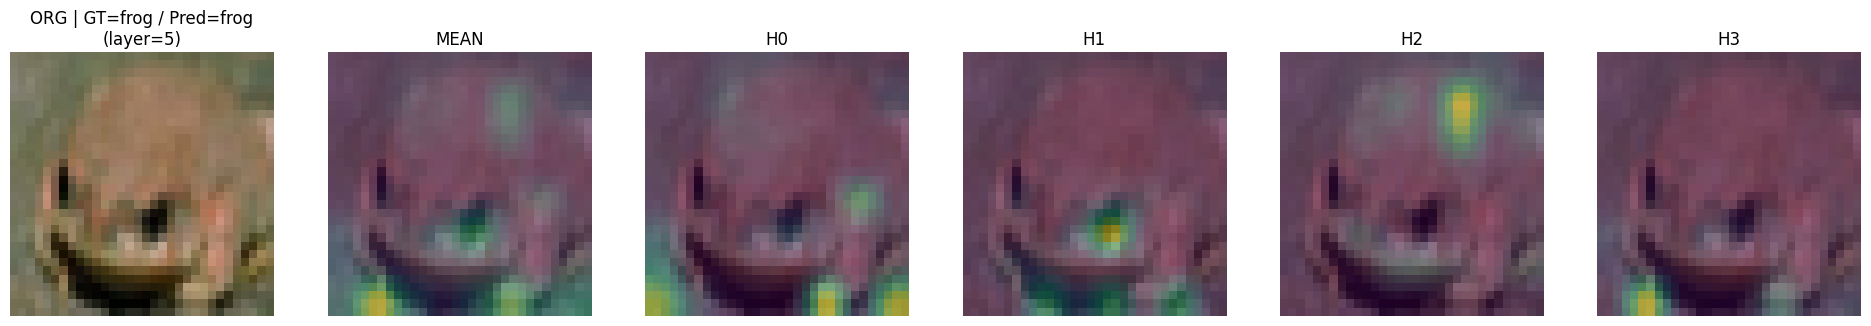

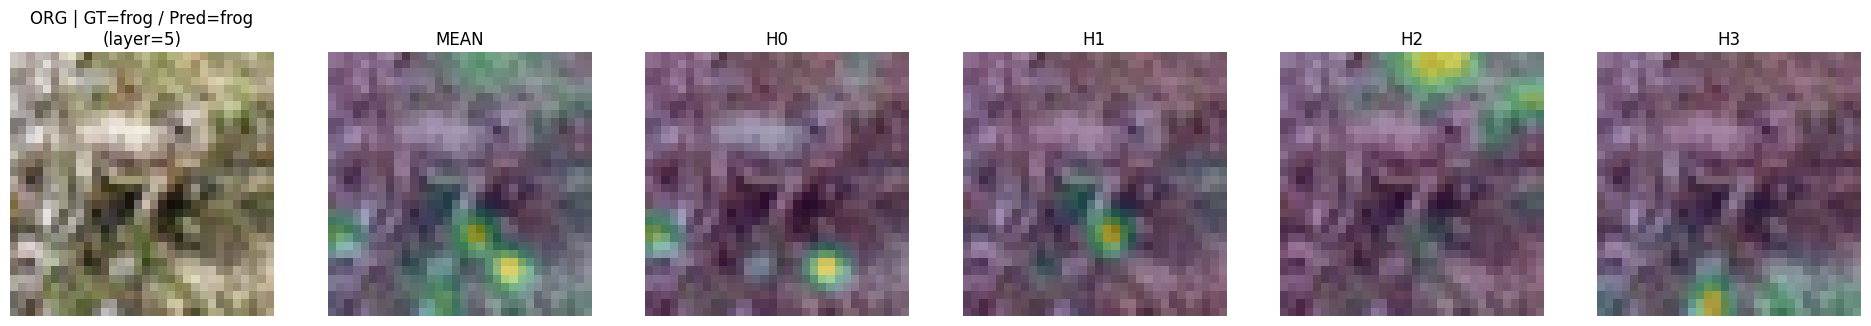

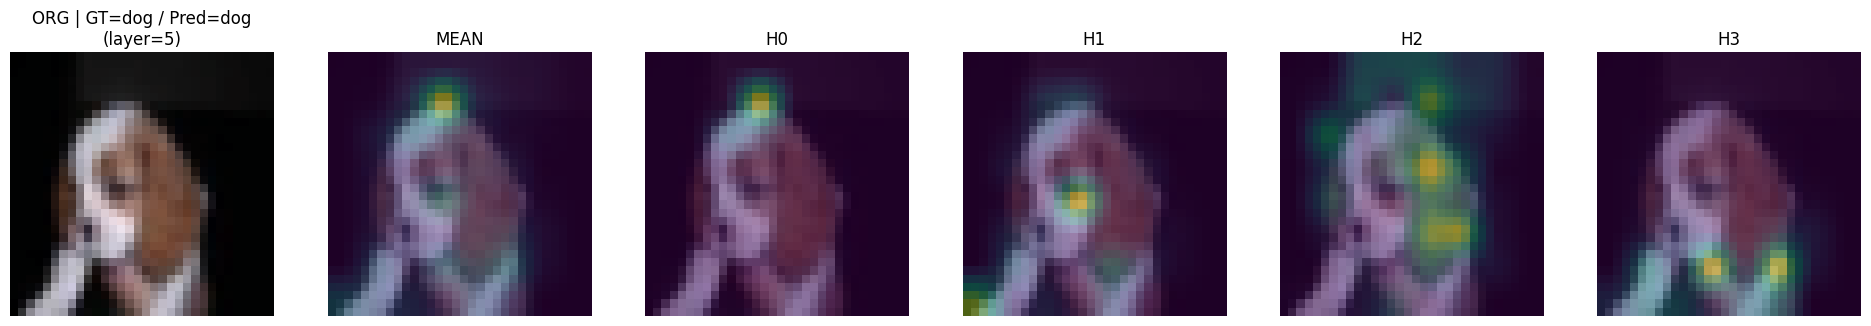

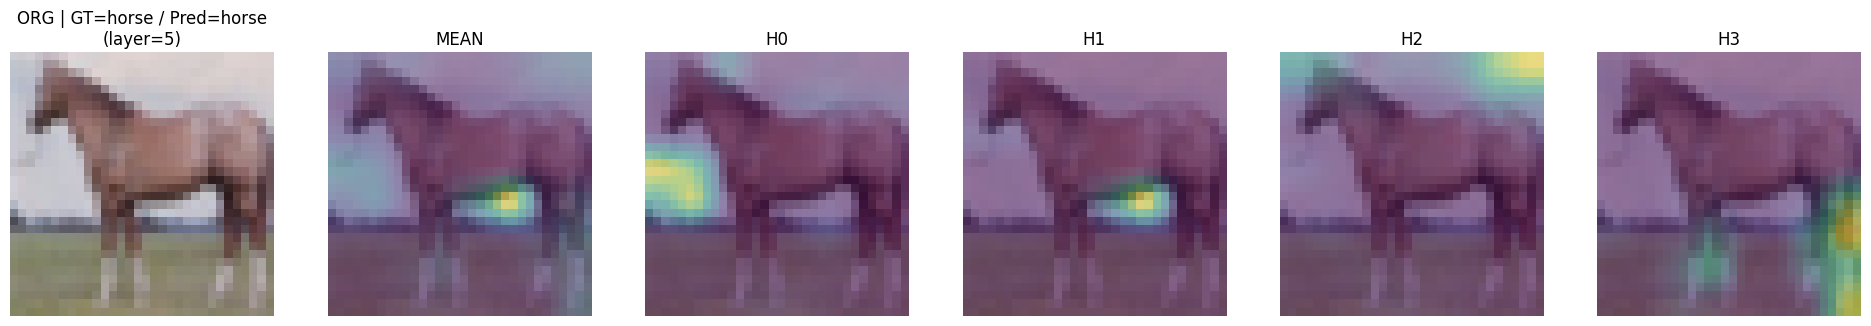

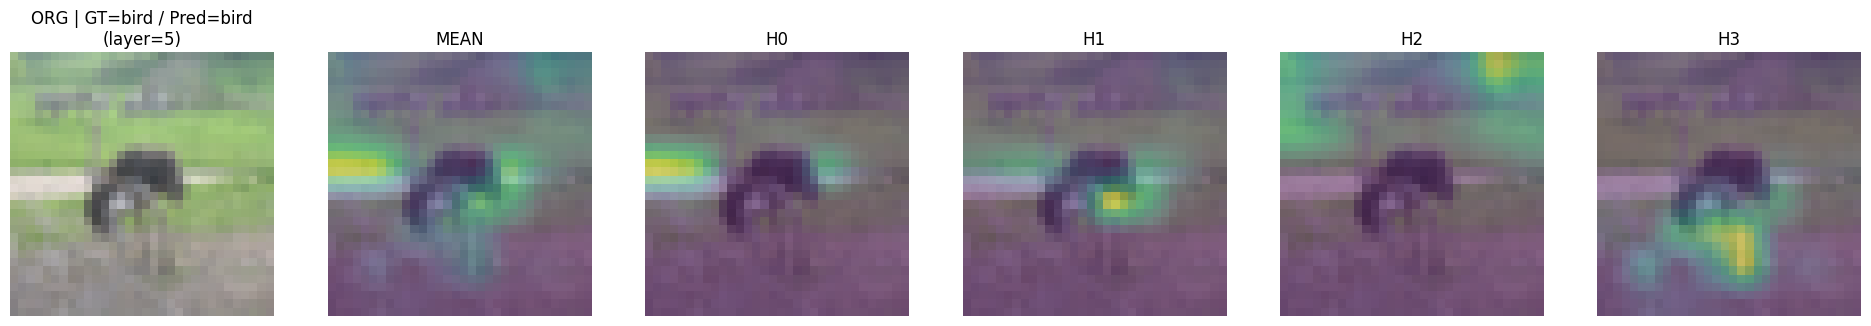

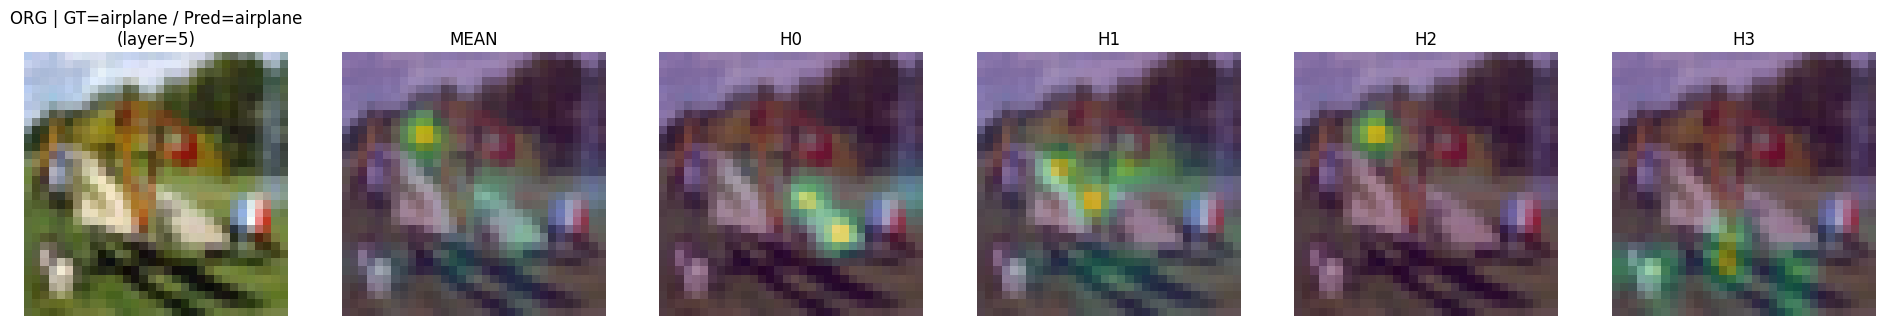

In [13]:
# 13
# (실습) Testing (Attention): ViT가 '어디를 보고' 예측했는지(=CLS→Patch Attention) 시각화
# - 마지막 logits는 CLS 토큰에서 나오므로, "CLS 토큰이 어떤 패치 토큰들을 참고했는지"를 보면 모델의 단서를 얻을 수 있습니다.
# - 실무/연구 관점에서도 초기 레이어(layer_idx=0)는 저수준/분산된 패턴이 많아 해석이 애매한 경우가 많아서,
#   기본값은 "맨 마지막 Transformer 블록"의 attention을 보는 쪽이 직관적입니다.
# - 또한 'head 평균'뿐 아니라 '각 head'가 서로 다른 패턴을 볼 수 있으므로, 여러 head를 한 번에 오버레이해서 비교합니다.

import matplotlib.pyplot as plt
import torch.nn.functional as F
import numpy as np
import random


def denormalize_cifar10_chw(img_chw: torch.Tensor):
    """정규화된 CIFAR-10 이미지(C,H,W)를 시각화용(0~1)으로 복원합니다."""
    mean = torch.tensor(CIFAR10_MEAN, device=img_chw.device)[:, None, None]
    std  = torch.tensor(CIFAR10_STD,  device=img_chw.device)[:, None, None]
    x = img_chw * std + mean
    return x.clamp(0, 1)


def chw_to_hwc_np(img_chw: torch.Tensor) -> np.ndarray:
    """(C,H,W) 텐서를 matplotlib imshow용 (H,W,C) numpy로 변환합니다.
    - CIFAR-10은 정규화가 적용되어 있으므로 denormalize 후 표시합니다.
    """
    x = denormalize_cifar10_chw(img_chw)  # (C,H,W), 0~1
    x = x.detach().cpu()
    # (C,H,W) -> (H,W,C)
    x_hwc = x.permute(1, 2, 0).numpy()
    return x_hwc

def imshow_chw(ax, img_chw: torch.Tensor, title: str = None):
    """CHW 텐서를 안전하게 imshow합니다."""
    x_hwc = chw_to_hwc_np(img_chw)
    ax.imshow(x_hwc)
    ax.axis("off")
    if title is not None:
        ax.set_title(title)


def _extract_last_attn(model, layer_idx: int):
    """지정한 encoder 블록(layer)의 Attention 모듈이 저장해둔 last_attn을 꺼냅니다.
    - Attention.forward에서 self.last_attn = attn.detach()로 저장하도록 구현되어 있어야 합니다.
    - 반환 shape: [B, H, N, N] (B=batch, H=head, N=tokens=1+num_patches)
    """
    # transformer.layers[layer_idx] = (PreNorm(Attention), PreNorm(FFN)) 형태를 가정
    attn_module = model.transformer.layers[layer_idx][0].fn  # [0]:Attention, [1]: FF, PreNorm(fn=Attention)
    attn = attn_module.last_attn
    if attn is None:
        raise RuntimeError("Attention.last_attn이 비어 있습니다. 먼저 model(x)를 한 번 forward 해야 합니다.")
    return attn  # [B,H,N,N]

def _cls_to_patch_map(attn_bhNN, head_idx=None):
    """[B,H,N,N] attention에서 CLS→Patch attention만 뽑아 1D로 반환합니다.
    - CLS 토큰 index = 0
    - Patch 토큰 index = 1..N
    - head_idx=None이면 head 평균을 사용합니다.
    반환: cls_attn_1d shape = [num_patches]
    """
    # CLS(0) 가 각 토큰(j)에 주는 attention: attn[..., 0, j]
    if head_idx is None:
        # head 평균: [B,N] (여기서는 B=1 가정)
        cls_attn = attn_bhNN.mean(dim=1)[0, 0, 1:]  # 평균 관심지도 [1, H, N+1, N+1] → [1, N+1, N+1] → [N]
    else:
        cls_attn = attn_bhNN[0, head_idx, 0, 1:]    # 특정헤드 관심지도 [N]
    return cls_attn

def _to_2d_grid(cls_attn_1d, grid_h: int, grid_w: int):
    """[num_patches] 1D attention을 (grid_h, grid_w)로 reshape합니다."""
    attn_2d = cls_attn_1d.reshape(grid_h, grid_w)
    # 0~1 범위로 정규화(시각화 안정성)
    attn_2d = attn_2d - attn_2d.min()
    attn_2d = attn_2d / (attn_2d.max() + 1e-8)
    return attn_2d

def _upsample_to_image(attn_2d, out_h: int, out_w: int):
    """(grid_h,grid_w) attention을 (out_h,out_w)로 bilinear upsample합니다."""
        # attn_2d가 이미 Tensor일 수도 있으므로, 불필요한 tensor(...) 재구성을 피합니다.
    if isinstance(attn_2d, torch.Tensor):
        attn_t = attn_2d.detach().float().unsqueeze(0).unsqueeze(0)  # [1,1,gh,gw] -> gray image
    else:
        attn_t = torch.as_tensor(attn_2d, dtype=torch.float32).unsqueeze(0).unsqueeze(0)  # [1,1,gh,gw] -> gray image
    attn_up = F.interpolate(attn_t, size=(out_h, out_w), mode="bilinear", align_corners=False)[0,0] # [32, 32]
    attn_up = attn_up - attn_up.min()
    attn_up = attn_up / (attn_up.max() + 1e-8)
    return attn_up.cpu().numpy()  # (out_h,out_w)

def _get_attention_maps_for_image(model, x1, vit_cfg, layer_idx=None, head_idx=None):
    """단일 이미지(x1)에 대해 attention map(overlay용)을 준비합니다.
    - layer_idx=None 또는 layer_idx==0 이면 '맨 마지막 레이어'로 자동 설정합니다(해석 용이).
    - head_idx=None 이면 'head 평균'을 반환.
    - head_idx가 정수면 해당 head만 반환.
    반환: (maps, used_layer_idx)
      - maps: list of (title, attn_up_HxW)
    """
    model.eval()
    with torch.no_grad():
        _ = model(x1)

    # (중요) 기본값: 마지막 레이어를 사용
    depth = int(vit_cfg.depth)
    used_layer_idx = (depth - 1) if (layer_idx is None or layer_idx == 0) else int(layer_idx)

    attn_bhNN = _extract_last_attn(model, used_layer_idx)  # [1,H,N,N]

    # patch grid 크기 = (H/patch, W/patch)
    ps = int(vit_cfg.patch_size) if not isinstance(vit_cfg.patch_size, tuple) else int(vit_cfg.patch_size[0])
    # 입력 이미지 크기 (CIFAR-10: 32x32, MNIST: HxW 등)에서 patch grid 크기를 계산합니다.
    if isinstance(vit_cfg.image_size, tuple):
        img_h, img_w = int(vit_cfg.image_size[0]), int(vit_cfg.image_size[1])
    else:
        img_h, img_w = int(vit_cfg.image_size), int(vit_cfg.image_size)

    grid_h, grid_w = img_h // ps, img_w // ps

    maps = []
    if head_idx is None:
        # head 평균 1장
        cls_1d = _cls_to_patch_map(attn_bhNN, head_idx=None)
        attn_2d = _to_2d_grid(cls_1d, grid_h, grid_w)
        maps.append(("MEAN", _upsample_to_image(attn_2d, out_h=img_h, out_w=img_w)))
    else:
        # 특정 head 1장
        cls_1d = _cls_to_patch_map(attn_bhNN, head_idx=int(head_idx))
        attn_2d = _to_2d_grid(cls_1d, grid_h, grid_w)
        maps.append((f"H{int(head_idx)}", _upsample_to_image(attn_2d, out_h=img_h, out_w=img_w)))

    return maps, used_layer_idx

def show_attention_overlays(
    model,
    test_set,
    vit_cfg,
    device,
    n_samples: int = 6,
    layer_idx=None,
    head_idx=None,
    show_all_heads: bool = True,
    sample_mode: str = "correct",  # "correct" | "incorrect" | "all"
    seed: int = 0,
):
    """여러 이미지에 대해 ORG(원본) + attention overlay를 나란히 보여줍니다.

    Args:
        model: 학습된 ViT 모델
        test_set: (image, label) 형태의 dataset
        vit_cfg: ViTConfig (depth, heads, patch_size 등)
        device: torch.device
        n_samples: 출력할 샘플 개수
        layer_idx: 보고 싶은 encoder 블록 인덱스
            - None 또는 0이면 마지막 레이어(depth-1)로 자동 설정(권장)
        head_idx: 보고 싶은 head 인덱스
            - None이면 head 평균(MEAN)
        show_all_heads: True면 마지막 레이어의 모든 head(H0..H{heads-1})도 함께 출력
        sample_mode: "correct"/"incorrect"/"all" 로 샘플 필터링
        seed: 랜덤 샘플링 재현성

    출력:
        각 샘플마다 [ORG] + [MEAN] + [H0..] 형태로 한 줄(row)로 표시합니다.
    """
    random.seed(seed)

    # 1) 샘플 후보 인덱스 준비
    indices = list(range(len(test_set)))

    # 2) 필요 시: 샘플 필터링 (correct/incorrect/all)
    # sample_mode에 따라 후보를 거릅니다.
    # - "correct"   : 정답(=맞춘) 샘플만
    # - "incorrect" : 오답(=틀린) 샘플만
    # - "all"       : 전체(필터 없음)
    sample_mode = (sample_mode or "all").lower().strip()
    if sample_mode not in {"correct", "incorrect", "all"}:
        print(f"[warn] sample_mode={sample_mode} 는 지원하지 않습니다. -> 'all'로 처리합니다.")
        sample_mode = "all"

    if sample_mode in {"correct", "incorrect"}:
        filtered = []
        model.eval()
        with torch.no_grad():
            for idx in indices:
                x, y = test_set[idx]
                x1 = x.unsqueeze(0).to(device)  # (1, 3, 32, 32)
                logits = model(x1)
                pred = int(logits.argmax(dim=1).item())
                is_correct = (pred == int(y))
                if (sample_mode == "correct" and is_correct) or (sample_mode == "incorrect" and (not is_correct)):
                    filtered.append(idx)

        indices = filtered
        if len(indices) == 0:
            msg = "정답" if sample_mode == "correct" else "오답"
            print(f"[warn] 조건에 맞는 {msg} 샘플이 없습니다. (모델 학습 상태/seed/n_samples를 확인하세요.)")
            return

    # 3) 샘플링
    chosen = random.sample(indices, k=min(n_samples, len(indices))) if len(indices) > 0 else []

    # 4) 시각화: 샘플마다 ORG + (MEAN + Heads) 를 한 row로 출력
    heads = int(vit_cfg.heads)
    for idx in chosen:
        x, y = test_set[idx]
        label = int(y)

        x1 = x.unsqueeze(0).to(device)
        model.eval()
        with torch.no_grad():
            logits = model(x1)
            pred = int(logits.argmax(dim=1).item())

        # (A) 평균 attention(MEAN)
        mean_maps, used_layer = _get_attention_maps_for_image(
            model=model, x1=x1, vit_cfg=vit_cfg,
            layer_idx=layer_idx, head_idx=None
        )

        # (B) 각 head attention(H0..)
        head_maps = []
        if show_all_heads:
            for h in range(heads):
                hm, _ = _get_attention_maps_for_image(
                    model=model, x1=x1, vit_cfg=vit_cfg,
                    layer_idx=layer_idx, head_idx=h
                )
                head_maps.extend(hm)  # hm은 1개짜리 리스트

        # 표시할 컬럼 구성: ORG + MEAN + heads...
        maps_to_show = mean_maps + head_maps

        ncols = 1 + len(maps_to_show)
        fig, axes = plt.subplots(1, ncols, figsize=(3.2 * ncols, 3.2))

        # ORG(원본)
        ax0 = axes[0]
        imshow_chw(ax0, x, title=None)
        ax0.axis("off")
        ax0.set_title(f"ORG | GT={class_names[int(label)]} / Pred={class_names[int(pred)]}\n(layer={used_layer})")

        # Overlays
        for j, (title, attn_up) in enumerate(maps_to_show, start=1):
            ax = axes[j]
            base = chw_to_hwc_np(x)  # (H,W,3), 0~1
            ax.imshow(base)
            ax.imshow(attn_up, alpha=0.45)  # heatmap overlay (컬러맵 기본값 사용)
            ax.axis("off")
            ax.set_title(f"{title}")

        plt.tight_layout()
        plt.show()

# 사용 예시:
# - 기본값(layer_idx=None): 마지막 레이어의 MEAN + 모든 head를 출력
# - sample_mode="incorrect": 오답 샘플만 골라서 보면 해석이 더 쉬운 경우가 많습니다.
show_attention_overlays(
    model=model,
    test_set=test_set,
    vit_cfg=vit_cfg,
    device=device,
    n_samples=6,
    layer_idx=None,           # None 또는 0이면 마지막 레이어를 사용
    head_idx=None,            # None이면 평균(MEAN)
    show_all_heads=True,      # 모든 head도 함께 보기
    sample_mode="correct",
    seed=0,
)

---
## 7) Confusion Matrix로 오분류 패턴 보기

- **목적:** 단순 정확도(accuracy)만으로는 보이지 않는 **클래스별 오분류 경향**을 확인합니다.
- **관찰 포인트:**
  - 어떤 클래스 쌍(예: `cat↔dog`, `automobile↔truck`, `deer↔horse`)이 자주 헷갈리는지
  - 특정 클래스에서만 오분류가 집중되는지(데이터/모델 편향 가능성)
  - 이후 `오분류 샘플 시각화`와 함께 보면 “왜” 틀렸는지 해석이 쉬워집니다.


### [셀 # 14] 코드 설명

**한 줄 요약:** 모델이 "어떤 클래스를 어떤 클래스로 자주 착각하는지"를 한눈에 보여 주는 표(혼동 행렬, confusion matrix)를 그립니다.

**코드 흐름**

1. `import seaborn as sns`, `from sklearn.metrics import confusion_matrix` — 예쁜 통계 그래프 도구와, 혼동 행렬 계산 함수를 불러옵니다.
2. `plot_confusion_matrix(model, data_loader)`
   - `all_preds = []`, `all_labels = []` : 예측과 정답을 모을 빈 리스트
   - 평가 모드 + `no_grad` 상태에서 테스트 배치를 차례로 모델에 넣습니다.
   - `_, preds = torch.max(output, dim=1)` : 점수가 가장 높은 클래스 번호가 예측입니다.
   - `all_preds.extend(preds.cpu().numpy())` : GPU에 있던 결과를 CPU의 numpy 배열로 옮겨 리스트에 이어 붙입니다.
   - `cm = confusion_matrix(all_labels, all_preds)` : 10×10 표를 만듭니다. **행 = 실제 정답, 열 = 모델의 예측**. 대각선은 맞힌 개수, 그 밖은 틀린 개수입니다.
   - `sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ...)` : 표를 색으로 칠합니다. `annot=True`는 칸마다 숫자를 표시, `fmt='d'`는 정수로 표시하라는 뜻입니다.
   - `plt.xlabel`, `plt.xticks(rotation=45)` 등 : 축 이름과 글자 각도를 다듬습니다.
3. 마지막 줄에서 함수를 실행합니다.

**보는 법:** 예를 들어 `cat` 행의 `dog` 열 숫자가 크면 "고양이를 개로 자주 착각한다"는 뜻입니다.

**Python 초보 포인트**

- `xticklabels=class_names` : 숫자 0~9 대신 클래스 이름을 눈금에 붙입니다.
- seaborn이나 scikit-learn이 없다는 에러가 나면 `ensure_package("seaborn")`, `ensure_package("scikit-learn", "sklearn")` 을 먼저 실행하세요.

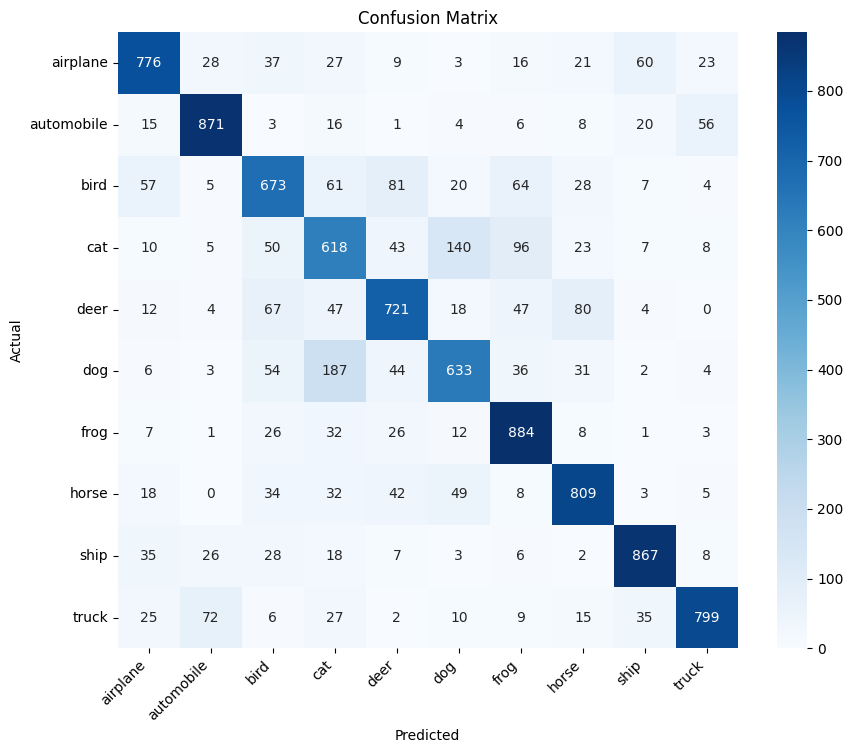

In [14]:
# 14
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

def plot_confusion_matrix(model, data_loader):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for data, target in data_loader:
            data = data.to(device)
            target = target.to(device)
            output = model(data)  # 입력 배치에 대한 모델 forward(로짓 출력)
            _, preds = torch.max(output, dim=1)   # preds = maximum indices
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(target.cpu().numpy())

    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted')
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)

    plt.ylabel('Actual')
    plt.title('Confusion Matrix')
    plt.show()

plot_confusion_matrix(model, test_loader)


---
## 8) 오분류(실패) 샘플만 시각화하기

- **목적:** 단순히 "맞춘 샘플"을 보는 것보다, **틀린 샘플(오분류)** 을 모아 보면 모델이 약한 패턴을 빠르게 파악할 수 있습니다.
- **어떻게 해석할까?**
  - 비슷한 클래스(예: `cat↔dog`, `automobile↔truck`)에서 헷갈리는지
  - 배경(하늘/풀/도로 등)이나 객체 크기/각도/가림(occlusion)에 민감한지
  - 데이터 증강(augmentation)이나 모델 크기/학습률 조절이 필요한지

아래 함수는 **오분류된 샘플만** 골라서 그려줍니다.


### [셀 # 15] 코드 설명

**한 줄 요약:** 모델이 **틀린 이미지만** 최대 10장 모아서, "정답(GT) / 예측(Pred)"을 제목으로 붙여 보여 줍니다.

**코드 흐름**

1. `mis_images, mis_labels, mis_preds = [], [], []` — 틀린 이미지·정답·예측을 담을 빈 리스트 3개를 한 줄로 만듭니다.
2. 테스트 배치를 돌면서:
   - `preds = logits.argmax(dim=1)` : 예측 클래스
   - `wrong_mask = preds.ne(target)` : 예측과 정답이 **다른**(not equal) 위치만 `True`인 목록
   - `if wrong_mask.any():` : 틀린 것이 하나라도 있으면
   - `data[wrong_mask]` : `True`인 위치의 이미지들만 골라냅니다(**불리언 인덱싱**).
   - `for x, y, p in zip(wrong_data, wrong_target, wrong_preds):` : 세 목록을 나란히 묶어 하나씩 꺼내 리스트에 추가합니다.
   - 10장이 차면 `break`로 반복을 빠져나옵니다. `break`는 가장 안쪽 반복문 하나만 끝내므로, 바깥 반복문도 끝내기 위해 같은 조건을 한 번 더 검사합니다.
3. 틀린 것이 없으면 안내 문구를 출력하고 `return`으로 함수를 끝냅니다.
4. 격자 준비: 5장 넘으면 2줄×5칸, 아니면 1줄. `axes = np.array(axes).reshape(-1)` 로 칸들을 한 줄 목록으로 펴서 `axes[i]`로 쉽게 접근합니다.
5. 각 칸에 정규화를 푼 이미지를 그리고 제목을 붙입니다. 남는 칸은 눈금만 숨깁니다.

**Python 초보 포인트**

- `zip(a, b, c)` : 여러 목록에서 같은 순번끼리 묶어 줍니다.
- `rows = 2 if n > 5 else 1` : 조건 표현식.
- `reshape(-1)` 의 `-1`은 "알아서 맞춰라"는 뜻으로, 여기서는 1차원으로 폅니다.
- `class_names[mis_labels[i]]` : 안쪽부터 읽습니다. i번째 정답 번호 → 그 번호의 클래스 이름.

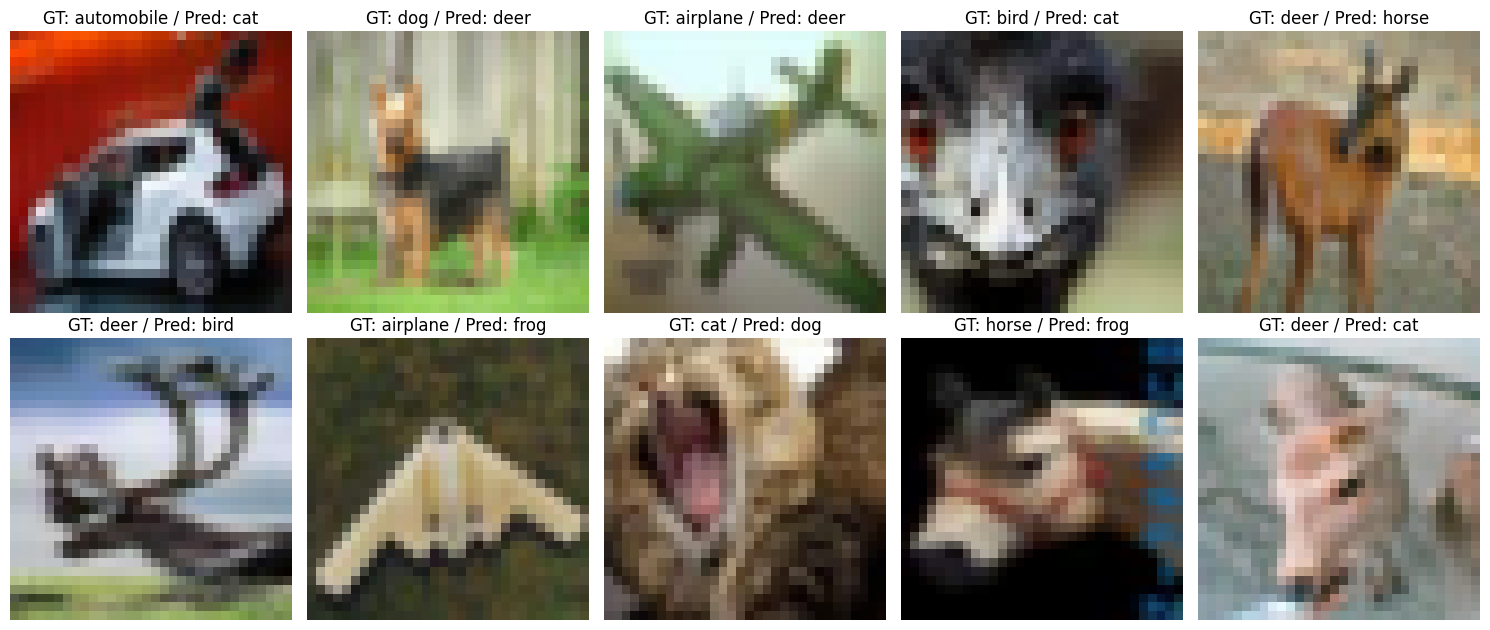

In [15]:
# 15
# 오분류(실패) 샘플만 시각화
def plot_misclassified_samples(model, data_loader, max_samples: int = 10):
    """테스트 데이터에서 오분류된 샘플만 골라 시각화합니다.

    Args:
        model: 학습된 분류 모델
        data_loader: (data, target)을 내는 DataLoader
        max_samples: 최대 출력 샘플 수 (기본 10)
    """
    model.eval()
    mis_images, mis_labels, mis_preds = [], [], []

    with torch.no_grad():
        for data, target in data_loader:
            data = data.to(device)
            target = target.to(device)

            logits = model(data)                 # [B, num_classes] 로짓
            preds = logits.argmax(dim=1)         # 각 샘플의 예측 클래스

            wrong_mask = preds.ne(target)        # 오분류 위치만 True
            if wrong_mask.any():
                # 오분류된 샘플만 추출
                wrong_data = data[wrong_mask].detach().cpu()  # keep as Tensor for denormalize
                wrong_target = target[wrong_mask].detach().cpu()
                wrong_preds = preds[wrong_mask].detach().cpu()

                for x, y, p in zip(wrong_data, wrong_target, wrong_preds):
                    mis_images.append(x)
                    mis_labels.append(int(y))
                    mis_preds.append(int(p))
                    if len(mis_images) >= max_samples:
                        break

            if len(mis_images) >= max_samples:
                break

    if len(mis_images) == 0:
        print("오분류 샘플이 없습니다. (현재 설정/에폭에서 테스트를 모두 맞췄을 가능성이 있습니다)")
        return

    # 시각화 그리드: 최대 10개를 2×5로 보기 좋게 배치
    n = min(len(mis_images), max_samples)
    rows = 2 if n > 5 else 1
    cols = 5 if n > 5 else n

    fig, axes = plt.subplots(rows, cols, figsize=(3*cols, 3.2*rows))
    axes = np.array(axes).reshape(-1)  # axes를 1D로 평탄화

    for i in range(rows * cols):
        ax = axes[i]
        if i < n:
            img_chw = mis_images[i]  # CIFAR-10: (3,32,32)
            img_vis = denormalize_cifar10(img_chw).detach().cpu().numpy().transpose(1, 2, 0)  # HWC
            ax.imshow(img_vis)
            ax.set_title(f"GT: {class_names[mis_labels[i]]} / Pred: {class_names[mis_preds[i]]}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()


# 실행: 오분류 샘플만 출력
plot_misclassified_samples(model, test_loader, max_samples=10)


---
## 9) (추가 실습) ONNX Export + Netron으로 구조 확인하기

- **목적:** ViT를 ONNX로 내보내고, Netron에서 *토큰화(패치 임베딩) → Transformer 블록 → Head* 흐름을 그래프로 확인합니다.
- **관찰 포인트:**
  - `print(model)` / `torchinfo.summary(...)`에서 본 레이어가 Netron 그래프에서 어떻게 연결되는지
  - 입력 텐서 크기(예: `[B, 3, 32, 32]`)가 중간에서 토큰 시퀀스(`[B, N, D]`)로 변환되는 지점이 어디인지


### [셀 # 16] 코드 설명

**한 줄 요약:** 학습된 모델을 **ONNX**라는 표준 파일 형식(`vit_cifar10.onnx`)으로 내보냅니다. 이 파일을 Netron(모델 구조 뷰어)에서 열면 모델 구조를 그림으로 볼 수 있습니다.

**코드 흐름**

1. `dummy = torch.randn(1, 3, 32, 32, device=device)` — 무작위 숫자로 채운 가짜 이미지 1장입니다. ONNX 변환기는 이 입력을 모델에 한 번 흘려 보내면서 계산 경로를 기록합니다.
2. `model.eval()` — 내보내기 전에 평가 모드로 둡니다.
3. `torch.onnx.export(model, dummy, onnx_path, ...)`
   - `input_names=["input"]`, `output_names=["logits"]` : 파일 안에서 입력/출력에 붙일 이름
   - `opset_version=17` : ONNX 연산 규격 버전
   - `do_constant_folding=True` : 미리 계산 가능한 부분은 정리해서 단순화
   - `dynamic_axes={"input": {0: "B"}, "logits": {0: "B"}}` : 0번 축(배치 크기)은 고정하지 않고 가변으로 둡니다. 이렇게 하면 1장이든 100장이든 넣을 수 있습니다.
4. `try/except` — `onnx` 패키지가 없는 등 문제가 생기면 에러 메시지와 힌트를 출력하고 넘어갑니다.

**Python 초보 포인트**

- 셀 위쪽의 `# ensure_package("onnx")` 는 주석 처리된 코드입니다. 맨 앞 `#`를 지우면 실행됩니다. 내보내기가 실패하면 이 두 줄의 주석을 풀고 다시 실행해 보세요.
- `{"input": {0: "B"}}` 는 딕셔너리 안에 딕셔너리가 들어 있는 구조입니다.
- 이 셀은 "추가 실습"이라 건너뛰어도 앞의 내용에는 영향이 없습니다.

In [16]:
# 16
# 필요 패키지 확인 (이미 ensure_package가 있다면 그걸 써도 됩니다)
# - onnx / onnxruntime는 환경에 따라 없을 수 있으니, 없으면 설치하세요.
# ensure_package("onnx")
# ensure_package("onnxruntime")

import torch

onnx_path = "vit_cifar10.onnx"
dummy = torch.randn(1, 3, 32, 32, device=device)  # CIFAR-10 입력 형식 (RGB, 32x32)
model.eval()

try:
    torch.onnx.export(
        model,
        dummy,
        onnx_path,
        input_names=["input"],
        output_names=["logits"],
        opset_version=17,
        do_constant_folding=True,
        dynamic_axes={"input": {0: "B"}, "logits": {0: "B"}},  # 배치 크기만 가변 처리
    )
    print("Saved ONNX:", onnx_path)
    print("Netron에서 열어서 (patch embedding → transformer blocks → head) 흐름을 확인해보세요.")
except Exception as e:
    print("ONNX export failed:", e)
    print("힌트: onnx 패키지가 없다면 `pip install onnx`가 필요할 수 있습니다.")


Saved ONNX: vit_cifar10.onnx
Netron에서 열어서 (patch embedding → transformer blocks → head) 흐름을 확인해보세요.
